# Balanced Force: Fourier Analysis and Spectrogram Comparison

This notebook compares hand-movement measurements for one healthy participant and one patient. It preserves the existing `plot_hand` function for raw and cropped signal inspection, then performs reproducible validation, channel aggregation, non-overlapping FFT analysis, and aligned spectrogram comparison.

> Input files must be trusted local RehaPiano result files because decoding uses `pickle.loads`.

## 1. Imports and global configuration

Configure the two filenames in this cell. All comparison parameters are shared by both participants so that differences in FFT and spectrogram output are not caused by different analysis settings.

In [1]:
import base64
import binascii
import json
import pickle
import pickletools
import struct
import zlib
from pathlib import Path
from typing import Optional

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.fft import rfft, rfftfreq
from scipy.signal import detrend, get_window, spectrogram

DATA_DIRECTORY_HEALTHY = Path("../../data/RehaPiano/09_09_2026/9_9_2026")
DATA_DIRECTORY_PATIENT = Path("../../data/RehaPiano/22_08_2025/")

HEALTHY_FILENAME = "results_d482c2df-d0be-4c89-bbdf-da1b2308cedc_20260909-131451"
PATIENT_FILENAME = "results_33eacf6b-6231-4dd5-863e-c3aa1e95d79b_20250417-101954"

s = 1000
n_start = 0.5
m_end = 0.5
window_lengths = [3, 5, 10]
spec_window = 2
MAX_FREQUENCY_HZ = 30
SAMPLING_RATE_WARNING_TOLERANCE = 0.05

LEFT_HAND_CHANNELS = list(range(0, 5))
RIGHT_HAND_CHANNELS = list(range(8, 13))
CHANNEL_COLUMNS = [f"channel_{index}" for index in range(16)]

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.figsize": (14, 5),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

In [2]:
def select_iteration(frame, iteration=None):
    if iteration is None:
        selected = frame.copy()
    else:
        available = sorted(frame["iteration"].unique())
        if iteration not in available:
            raise ValueError(f"Ітерація має бути однією з {available}")
        selected = frame.loc[frame["iteration"] == iteration].copy()

    selected["plot_seconds"] = selected.groupby("iteration")["timestamp_ms"].transform(
        lambda values: (values - values.iloc[0]) / 1000
    )
    return selected

def validate_hand(hand):
    normalized = hand.lower()
    if normalized not in {"left", "right"}:
        raise ValueError("Рука має бути 'left' або 'right'")
    return normalized

In [3]:
def plot_hand(frame, hand, iteration=None):
    hand = validate_hand(hand)
    channels = LEFT_HAND_CHANNELS if hand == "left" else RIGHT_HAND_CHANNELS
    selected = select_iteration(frame, iteration)
    hand_label = "left hand" if hand == "left" else "right hand"

    iterations = sorted(selected["iteration"].unique())
    fig, axes = plt.subplots(
        len(iterations),
        1,
        figsize=(14, max(5, 3.5 * len(iterations))),
        sharex=False,
        squeeze=False,
    )

    for ax, iteration_number in zip(axes.flat, iterations):
        group = selected.loc[selected["iteration"] == iteration_number]
        for channel in channels:
            ax.plot(
                group["plot_seconds"],
                group[f"channel_{channel}"],
                linewidth=1,
                label=f"channel {channel}",
            )
        ax.set_title(f"{hand_label.capitalize()}, iteration {iteration_number}")
        ax.set_xlabel("Time from start of iteration, s")
        ax.set_ylabel("Amplitude")
        ax.legend(ncol=5)
        ax.grid(alpha=0.25)

    fig.tight_layout()
    plt.show()

## 2. Trusted measurement loading

The encoded `raw` field is decoded in reverse order: Base64, zlib, trusted pickle, then 72-byte samples using `<Q16f`. The timestamp is an unsigned 64-bit integer in milliseconds, not a floating-point value.

In [4]:
SAMPLE_STRUCT = struct.Struct("<Q16f")
UNSAFE_PICKLE_OPCODES = {
    "GLOBAL", "STACK_GLOBAL", "REDUCE", "NEWOBJ", "NEWOBJ_EX",
    "OBJ", "INST", "EXT1", "EXT2", "EXT4", "PERSID", "BINPERSID",
}


def load_measurement_file(file_path: Path) -> tuple[pd.DataFrame, dict]:
    path = Path(file_path).expanduser()
    if not path.is_file():
        raise FileNotFoundError(f"Measurement file not found: {path}")

    try:
        with path.open("r", encoding="utf-8") as file:
            document = json.load(file)
    except json.JSONDecodeError as error:
        raise ValueError(f"Invalid JSON in {path}: {error}") from error

    payload = document.get("payload")
    if not isinstance(payload, dict):
        raise ValueError(f"{path} does not contain a payload object")

    required_fields = {"examination_id", "step_id", "additional_data", "raw"}
    missing_fields = sorted(required_fields.difference(payload))
    if missing_fields:
        raise ValueError(f"Missing payload fields in {path}: {missing_fields}")

    try:
        compressed = base64.b64decode(payload["raw"], validate=True)
    except (binascii.Error, ValueError, TypeError) as error:
        raise ValueError(f"Invalid Base64 payload in {path}") from error

    try:
        pickled_data = zlib.decompress(compressed)
    except zlib.error as error:
        raise ValueError(f"Invalid zlib payload in {path}: {error}") from error

    try:
        unsafe_opcodes = sorted({
            opcode.name
            for opcode, _, _ in pickletools.genops(pickled_data)
            if opcode.name in UNSAFE_PICKLE_OPCODES
        })
    except Exception as error:
        raise ValueError(f"Invalid pickle stream in {path}: {error}") from error
    if unsafe_opcodes:
        raise ValueError(f"Unsafe pickle opcodes detected in {path}: {unsafe_opcodes}")

    try:
        iterations = pickle.loads(pickled_data)
    except Exception as error:
        raise ValueError(f"Could not deserialize trusted pickle data in {path}: {error}") from error

    rows = []
    skipped_none = 0
    for iteration_number, iteration in enumerate(iterations, start=1):
        for sample_number, sample in enumerate(iteration):
            if sample is None:
                skipped_none += 1
                continue
            if not isinstance(sample, bytes) or len(sample) != SAMPLE_STRUCT.size:
                actual_size = len(sample) if hasattr(sample, "__len__") else "unknown"
                raise ValueError(
                    f"Iteration {iteration_number}, sample {sample_number} in {path}: "
                    f"expected 72 bytes, received {actual_size}"
                )

            timestamp_ms, *channels = SAMPLE_STRUCT.unpack(sample)
            rows.append({
                "examination_id": payload["examination_id"],
                "step_id": payload["step_id"],
                "iteration": iteration_number,
                "sample": sample_number,
                "timestamp_ms": timestamp_ms,
                **{f"channel_{index}": value for index, value in enumerate(channels)},
            })

    if not rows:
        raise ValueError(f"No valid samples found in {path}")

    try:
        additional_data = json.loads(payload["additional_data"] or "{}")
    except json.JSONDecodeError as error:
        raise ValueError(f"Invalid additional_data JSON in {path}: {error}") from error

    frame = pd.DataFrame(rows)
    frame["datetime_utc"] = pd.to_datetime(frame["timestamp_ms"], unit="ms", utc=True)
    frame["elapsed_seconds"] = (
        frame["timestamp_ms"] - frame["timestamp_ms"].iloc[0]
    ) / 1000

    duration_seconds = (
        frame["timestamp_ms"].iloc[-1] - frame["timestamp_ms"].iloc[0]
    ) / 1000
    metadata = {
        "file": str(path),
        "examination_id": payload["examination_id"],
        "step_id": payload["step_id"],
        "additional_data": additional_data,
        "iterations": len(iterations),
        "valid_samples": len(frame),
        "skipped_none_samples": skipped_none,
        "timestamp_duration_seconds": duration_seconds,
        "dataframe_shape": frame.shape,
    }
    return frame, metadata


def display_measurement_metadata(label: str, metadata: dict) -> None:
    print(f"{label} measurement")
    display(pd.Series(metadata, name="value").to_frame())

In [5]:
healthy_frame, healthy_metadata = load_measurement_file(DATA_DIRECTORY_HEALTHY / HEALTHY_FILENAME)
patient_frame, patient_metadata = load_measurement_file(DATA_DIRECTORY_PATIENT / PATIENT_FILENAME)

healthy_frame["participant"] = "Healthy"
patient_frame["participant"] = "Patient"

display_measurement_metadata("Healthy", healthy_metadata)
display_measurement_metadata("Patient", patient_metadata)

if healthy_metadata["step_id"] != patient_metadata["step_id"]:
    print(
        "WARNING: configured files have different step IDs: "
        f"{healthy_metadata['step_id']} vs {patient_metadata['step_id']}"
    )

Healthy measurement


,value
file,../../data/RehaPiano/09_09_2026/9_9_2026/resul...
examination_id,d482c2df-d0be-4c89-bbdf-da1b2308cedc
step_id,5867ebbc-a463-4d20-8b20-50df7c64ace7
additional_data,{}
iterations,4
valid_samples,64194
skipped_none_samples,0
timestamp_duration_seconds,70.646
dataframe_shape,"(64194, 23)"


Patient measurement


,value
file,../../data/RehaPiano/22_08_2025/results_33eacf...
examination_id,33eacf6b-6231-4dd5-863e-c3aa1e95d79b
step_id,d2e6b7bd-a952-4652-afe3-9888e29ac205
additional_data,{}
iterations,4
valid_samples,64166
skipped_none_samples,0
timestamp_duration_seconds,70.61
dataframe_shape,"(64166, 23)"


## 3. Data validation

Validation reports channel completeness, timestamp quality, non-finite values, estimated sampling rate, and sample counts per iteration. The configured rate `s` remains the rate used for both participants even if timestamps indicate a noticeable difference.

In [6]:
def validate_measurement_data(
    frame: pd.DataFrame,
    participant: str,
    configured_rate: float,
) -> dict:
    missing_columns = sorted(set(CHANNEL_COLUMNS).difference(frame.columns))
    if missing_columns:
        raise ValueError(f"{participant}: missing channel columns {missing_columns}")
    if frame["timestamp_ms"].isna().any():
        raise ValueError(f"{participant}: timestamp_ms contains missing values")

    timestamps = frame["timestamp_ms"].to_numpy(dtype=np.int64)
    timestamp_differences = np.diff(timestamps)
    positive_differences = timestamp_differences[timestamp_differences > 0]
    if positive_differences.size == 0:
        raise ValueError(f"{participant}: no positive timestamp differences")

    channel_values = frame[CHANNEL_COLUMNS].to_numpy(dtype=float)
    missing_values = int(np.isnan(channel_values).sum())
    non_finite_values = int((~np.isfinite(channel_values)).sum())
    median_delta_ms = float(np.median(positive_differences))
    estimated_rate = 1000 / median_delta_ms
    relative_rate_error = abs(estimated_rate - configured_rate) / configured_rate

    report = {
        "participant": participant,
        "samples": len(frame),
        "timestamps_monotonic_non_decreasing": bool(frame["timestamp_ms"].is_monotonic_increasing),
        "duplicate_timestamps": int(frame["timestamp_ms"].duplicated().sum()),
        "backward_timestamp_steps": int((timestamp_differences < 0).sum()),
        "timestamp_gaps_above_1.5x_median": int(
            (timestamp_differences > 1.5 * median_delta_ms).sum()
        ),
        "median_timestamp_delta_ms": median_delta_ms,
        "estimated_sampling_rate_hz": estimated_rate,
        "configured_sampling_rate_hz": configured_rate,
        "missing_channel_values": missing_values,
        "non_finite_channel_values": non_finite_values,
    }

    print(f"\n{participant} validation")
    display(pd.Series(report, name="value").to_frame())
    display(
        frame.groupby("iteration", sort=False)
        .size()
        .rename("sample_count")
        .to_frame()
    )
    if relative_rate_error > SAMPLING_RATE_WARNING_TOLERANCE:
        print(
            f"WARNING: {participant} timestamp-derived rate is {estimated_rate:.2f} Hz, "
            f"which differs from configured s={configured_rate} Hz by "
            f"{relative_rate_error:.1%}. The configured rate will still be used."
        )
    return report


healthy_validation = validate_measurement_data(healthy_frame, "Healthy", s)
patient_validation = validate_measurement_data(patient_frame, "Patient", s)


Healthy validation


,value
participant,Healthy
samples,64194
timestamps_monotonic_non_decreasing,True
duplicate_timestamps,14861
backward_timestamp_steps,0
timestamp_gaps_above_1.5x_median,12680
median_timestamp_delta_ms,1.0
estimated_sampling_rate_hz,1000.0
configured_sampling_rate_hz,1000
missing_channel_values,728


,sample_count
iteration,
1,16040
2,16056
3,16047
4,16051



Patient validation


,value
participant,Patient
samples,64166
timestamps_monotonic_non_decreasing,True
duplicate_timestamps,15196
backward_timestamp_steps,0
timestamp_gaps_above_1.5x_median,12785
median_timestamp_delta_ms,1.0
estimated_sampling_rate_hz,1000.0
configured_sampling_rate_hz,1000
missing_channel_values,872


,sample_count
iteration,
1,16043
2,16043
3,16042
4,16038


## 4. Raw signal inspection

The existing `plot_hand` function is reused without redefining it. Each call shows the five sensor channels for one hand across the original iterations.

Healthy - Left Hand - Raw


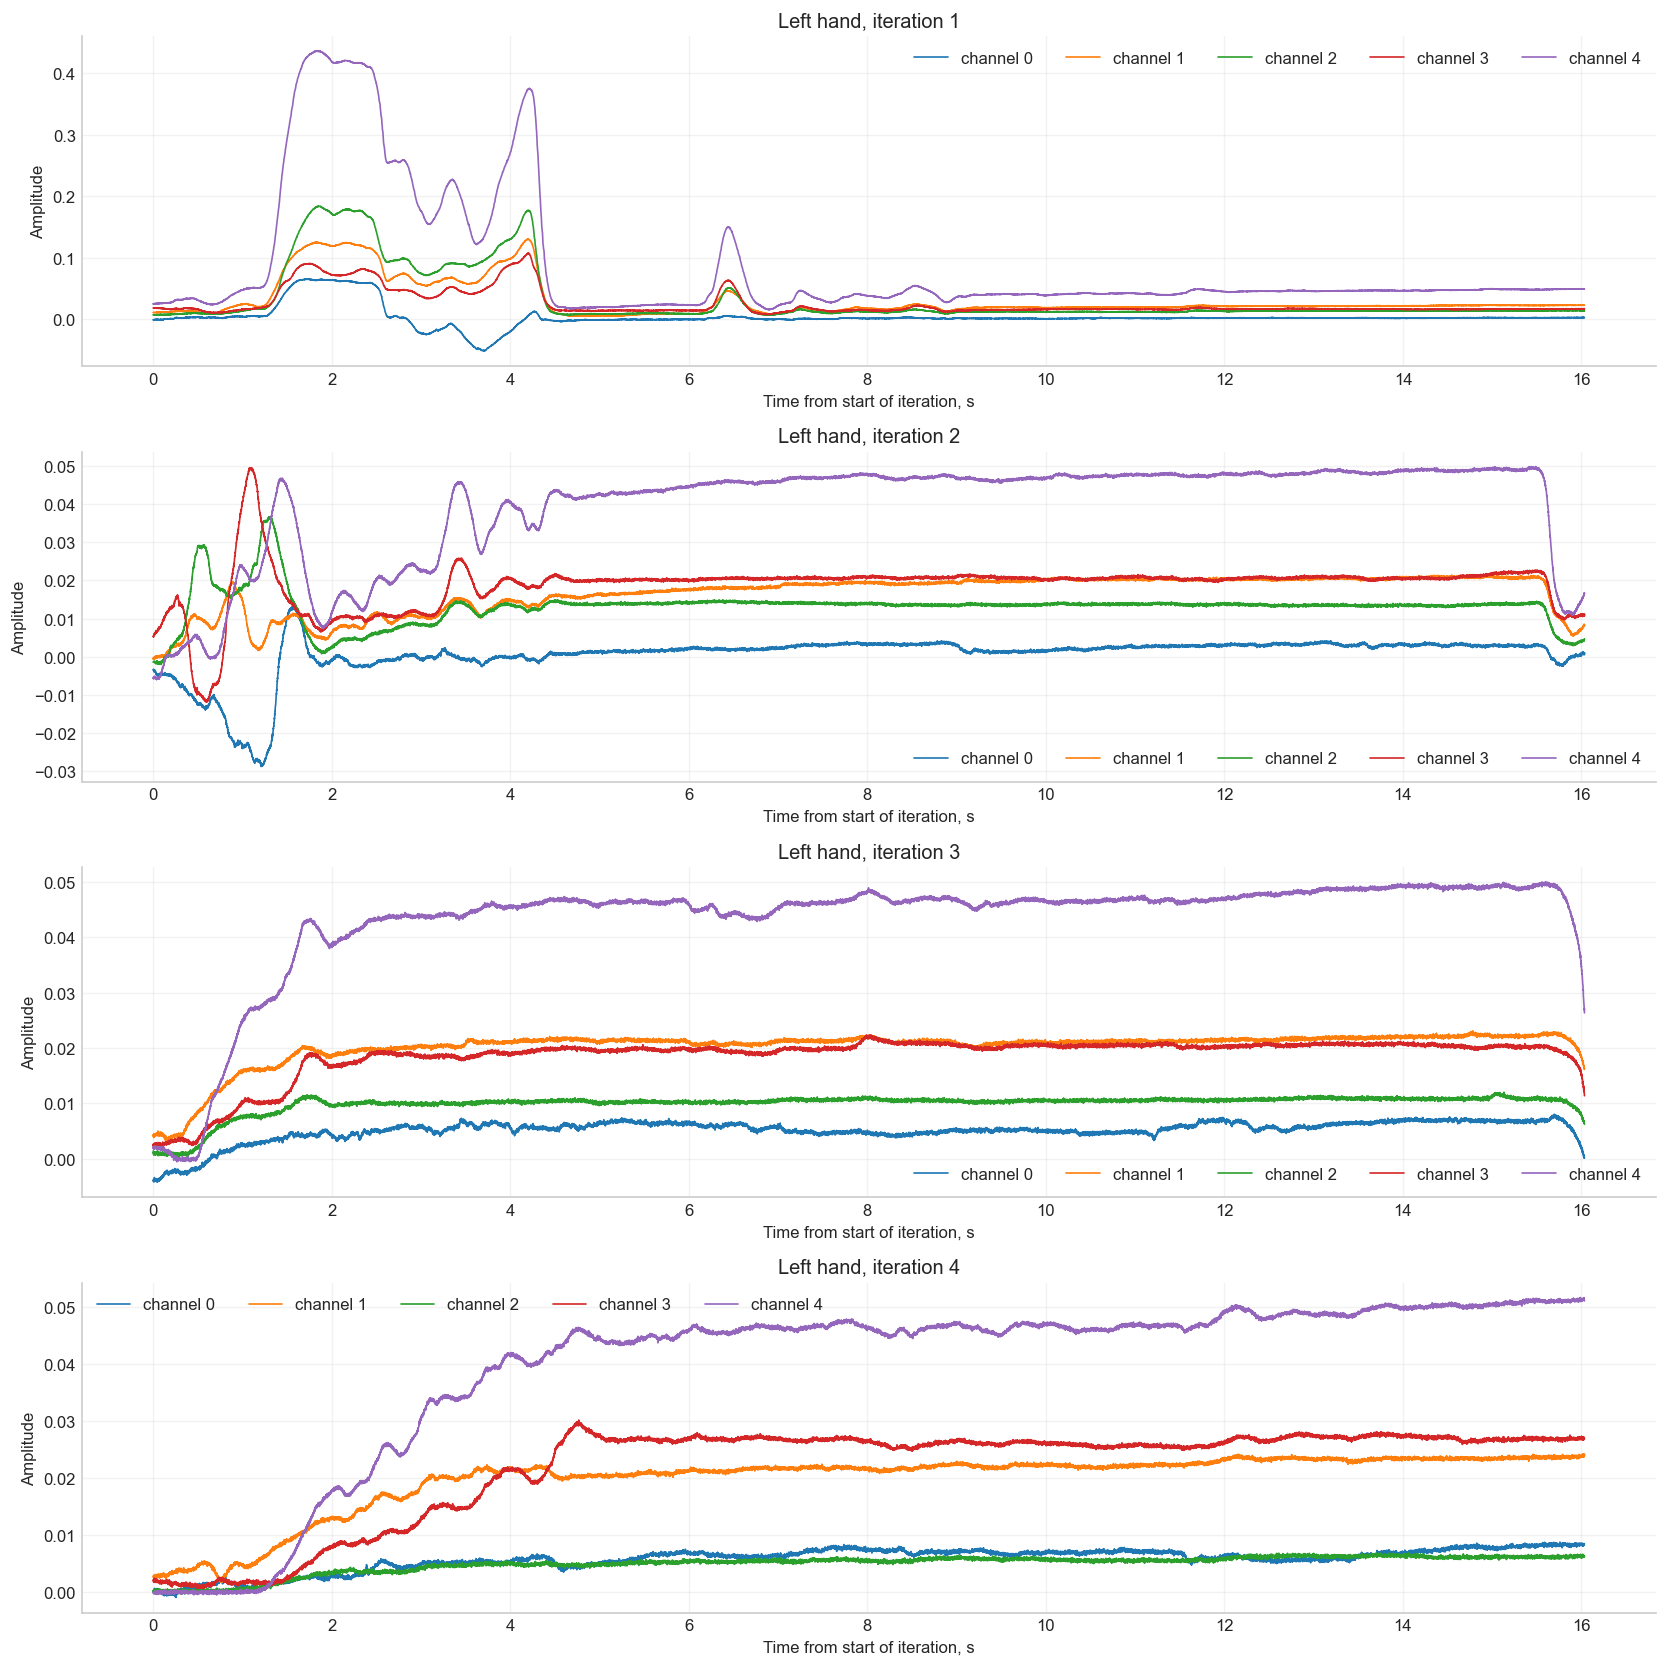

Healthy - Right Hand - Raw


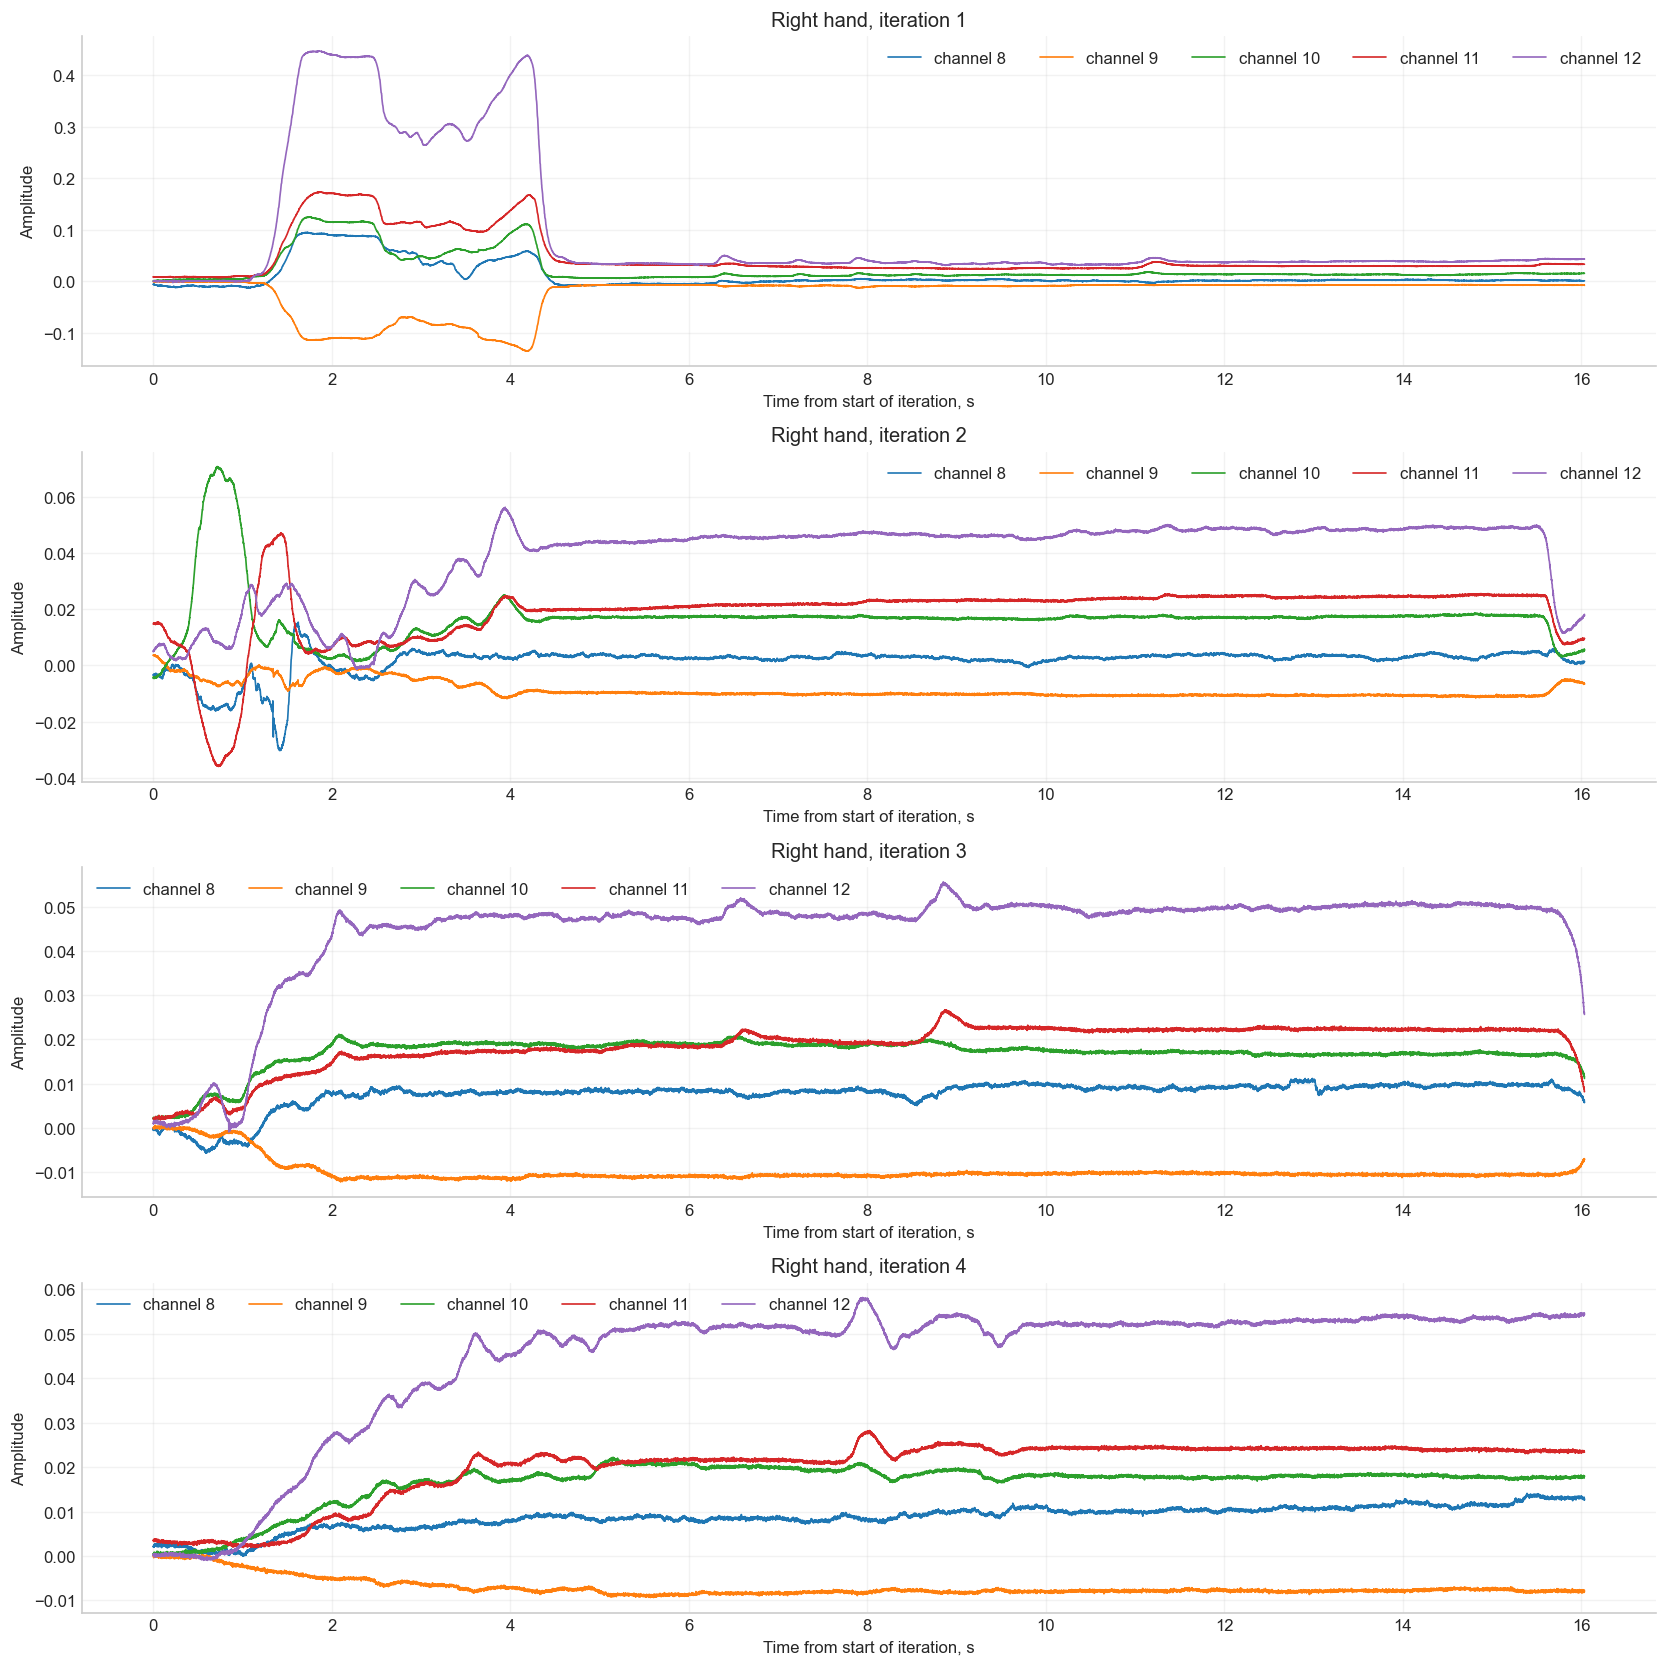

Patient - Left Hand - Raw


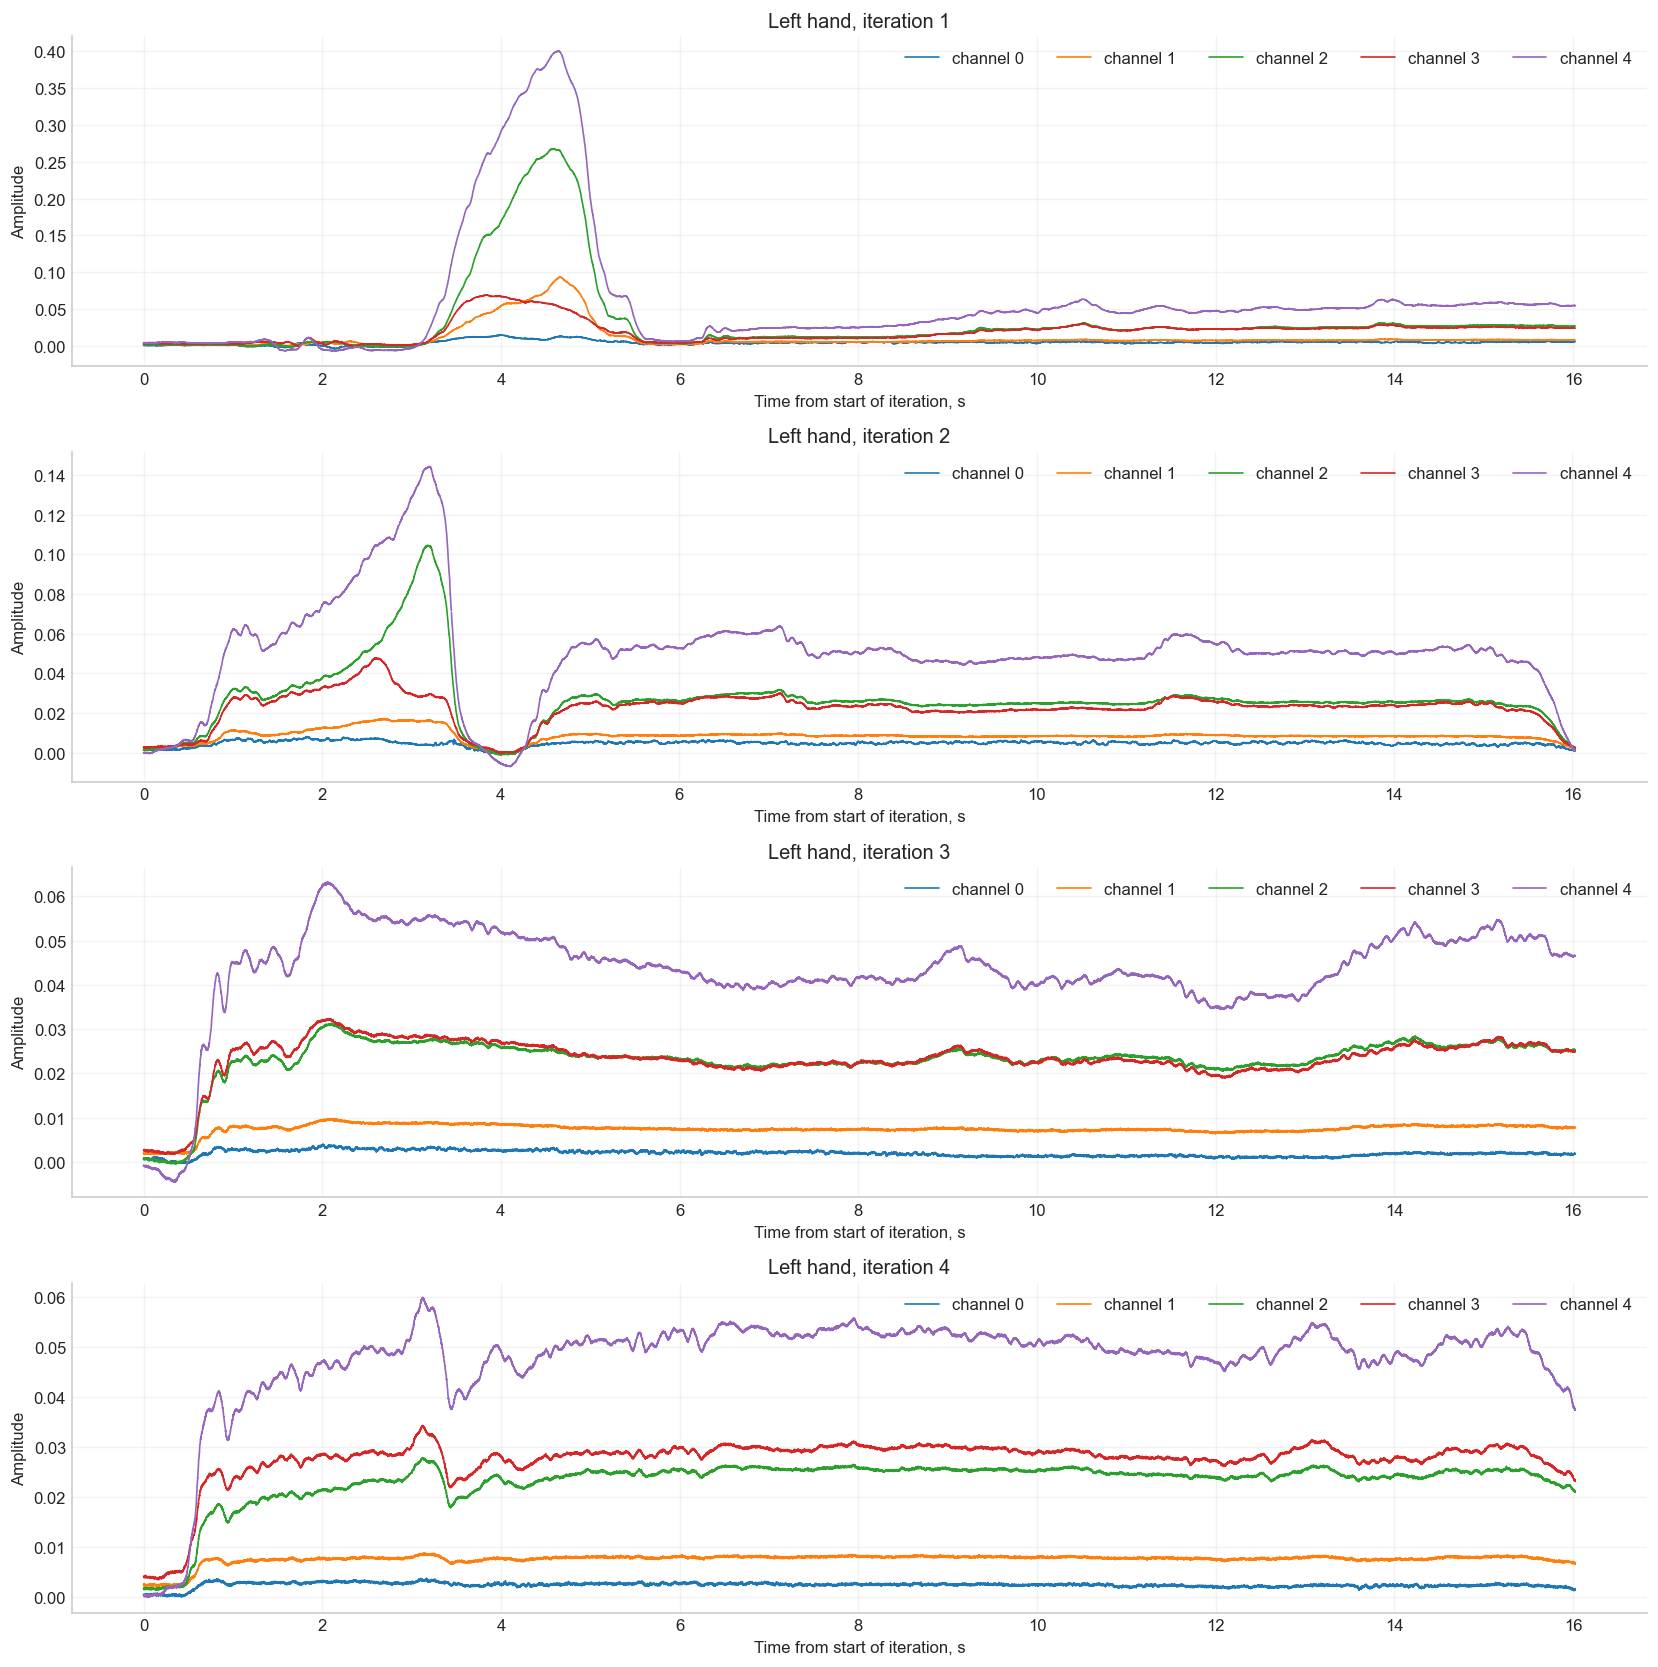

Patient - Right Hand - Raw


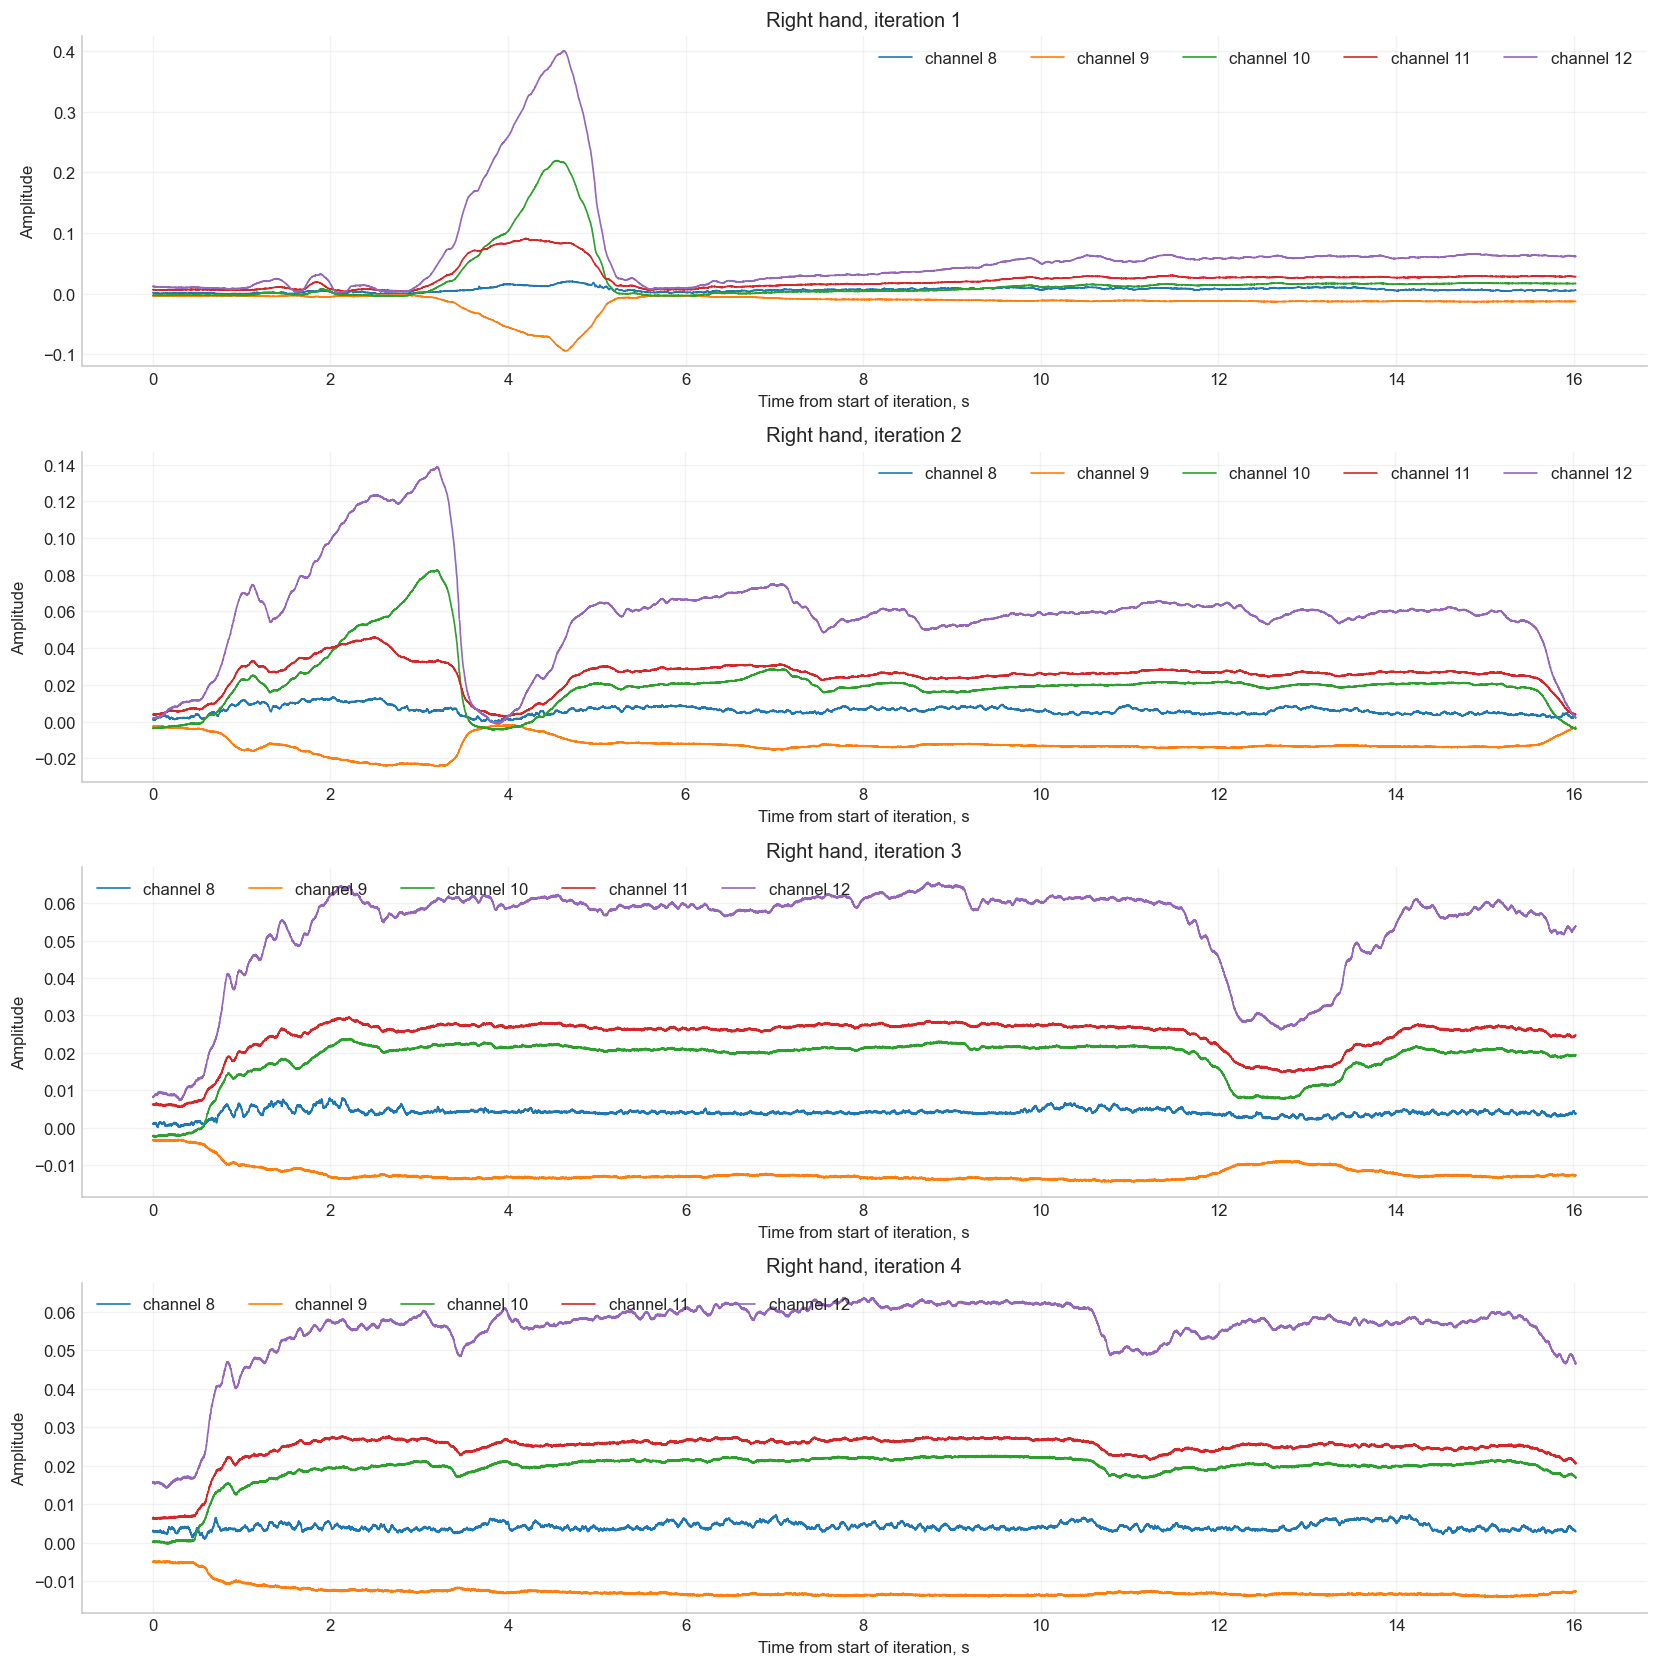

In [7]:
for participant, frame in (("Healthy", healthy_frame), ("Patient", patient_frame)):
    for hand in ("left", "right"):
        print(f"{participant} - {hand.title()} Hand - Raw")
        plot_hand(frame, hand=hand)

## 5. Crop boundaries and post-crop inspection

The first `n_start` seconds and last `m_end` seconds are removed using sample positions derived from the shared configured sampling rate. Original timestamps and iteration labels are preserved.

Healthy - Left Hand - Cropped


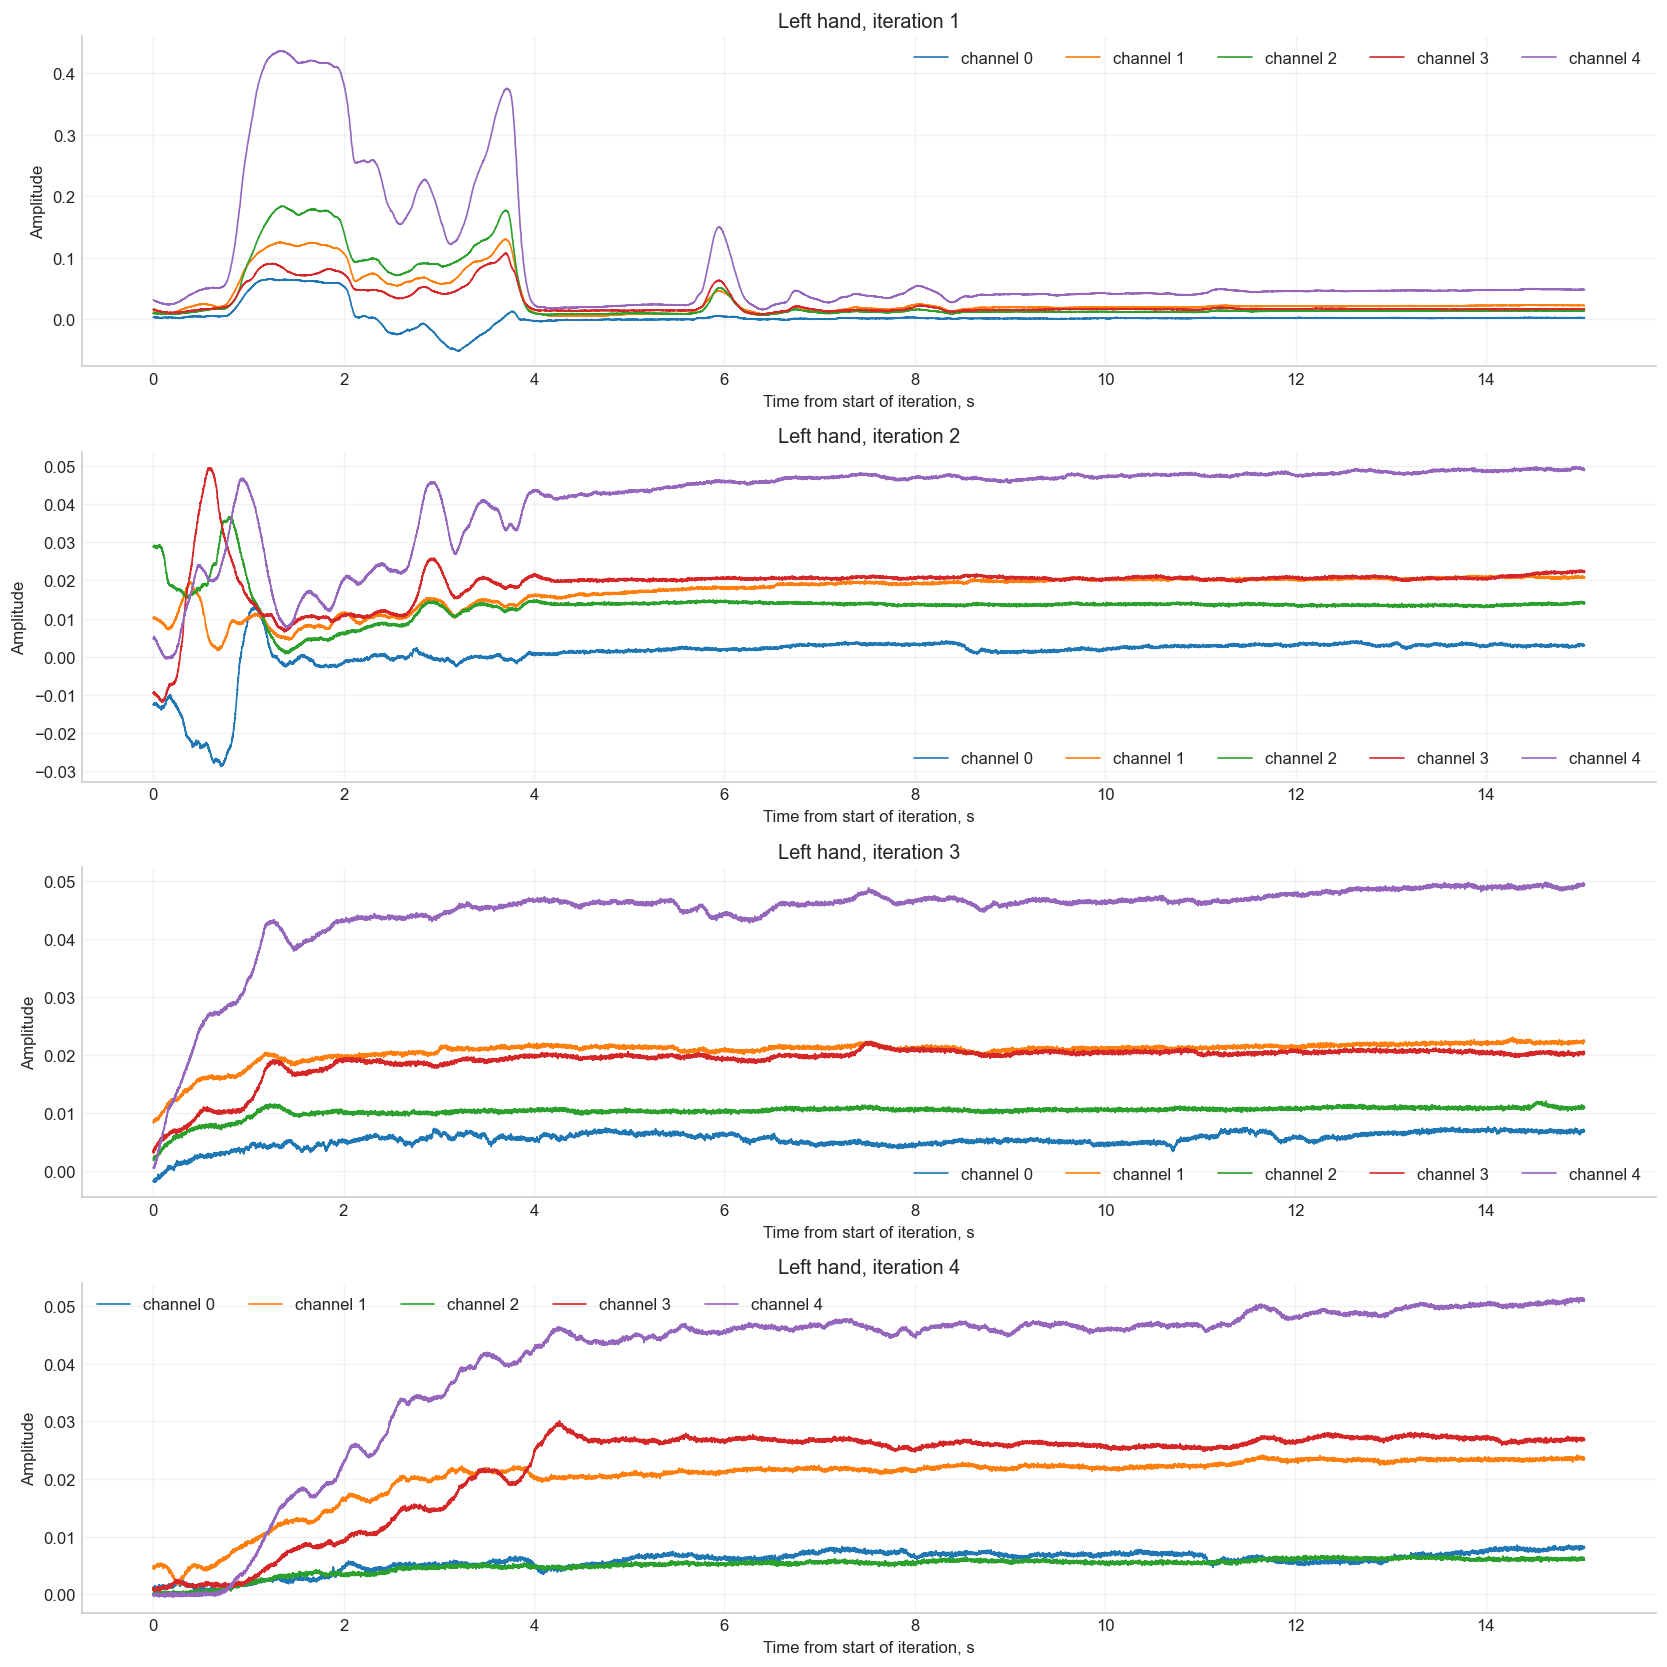

Healthy - Right Hand - Cropped


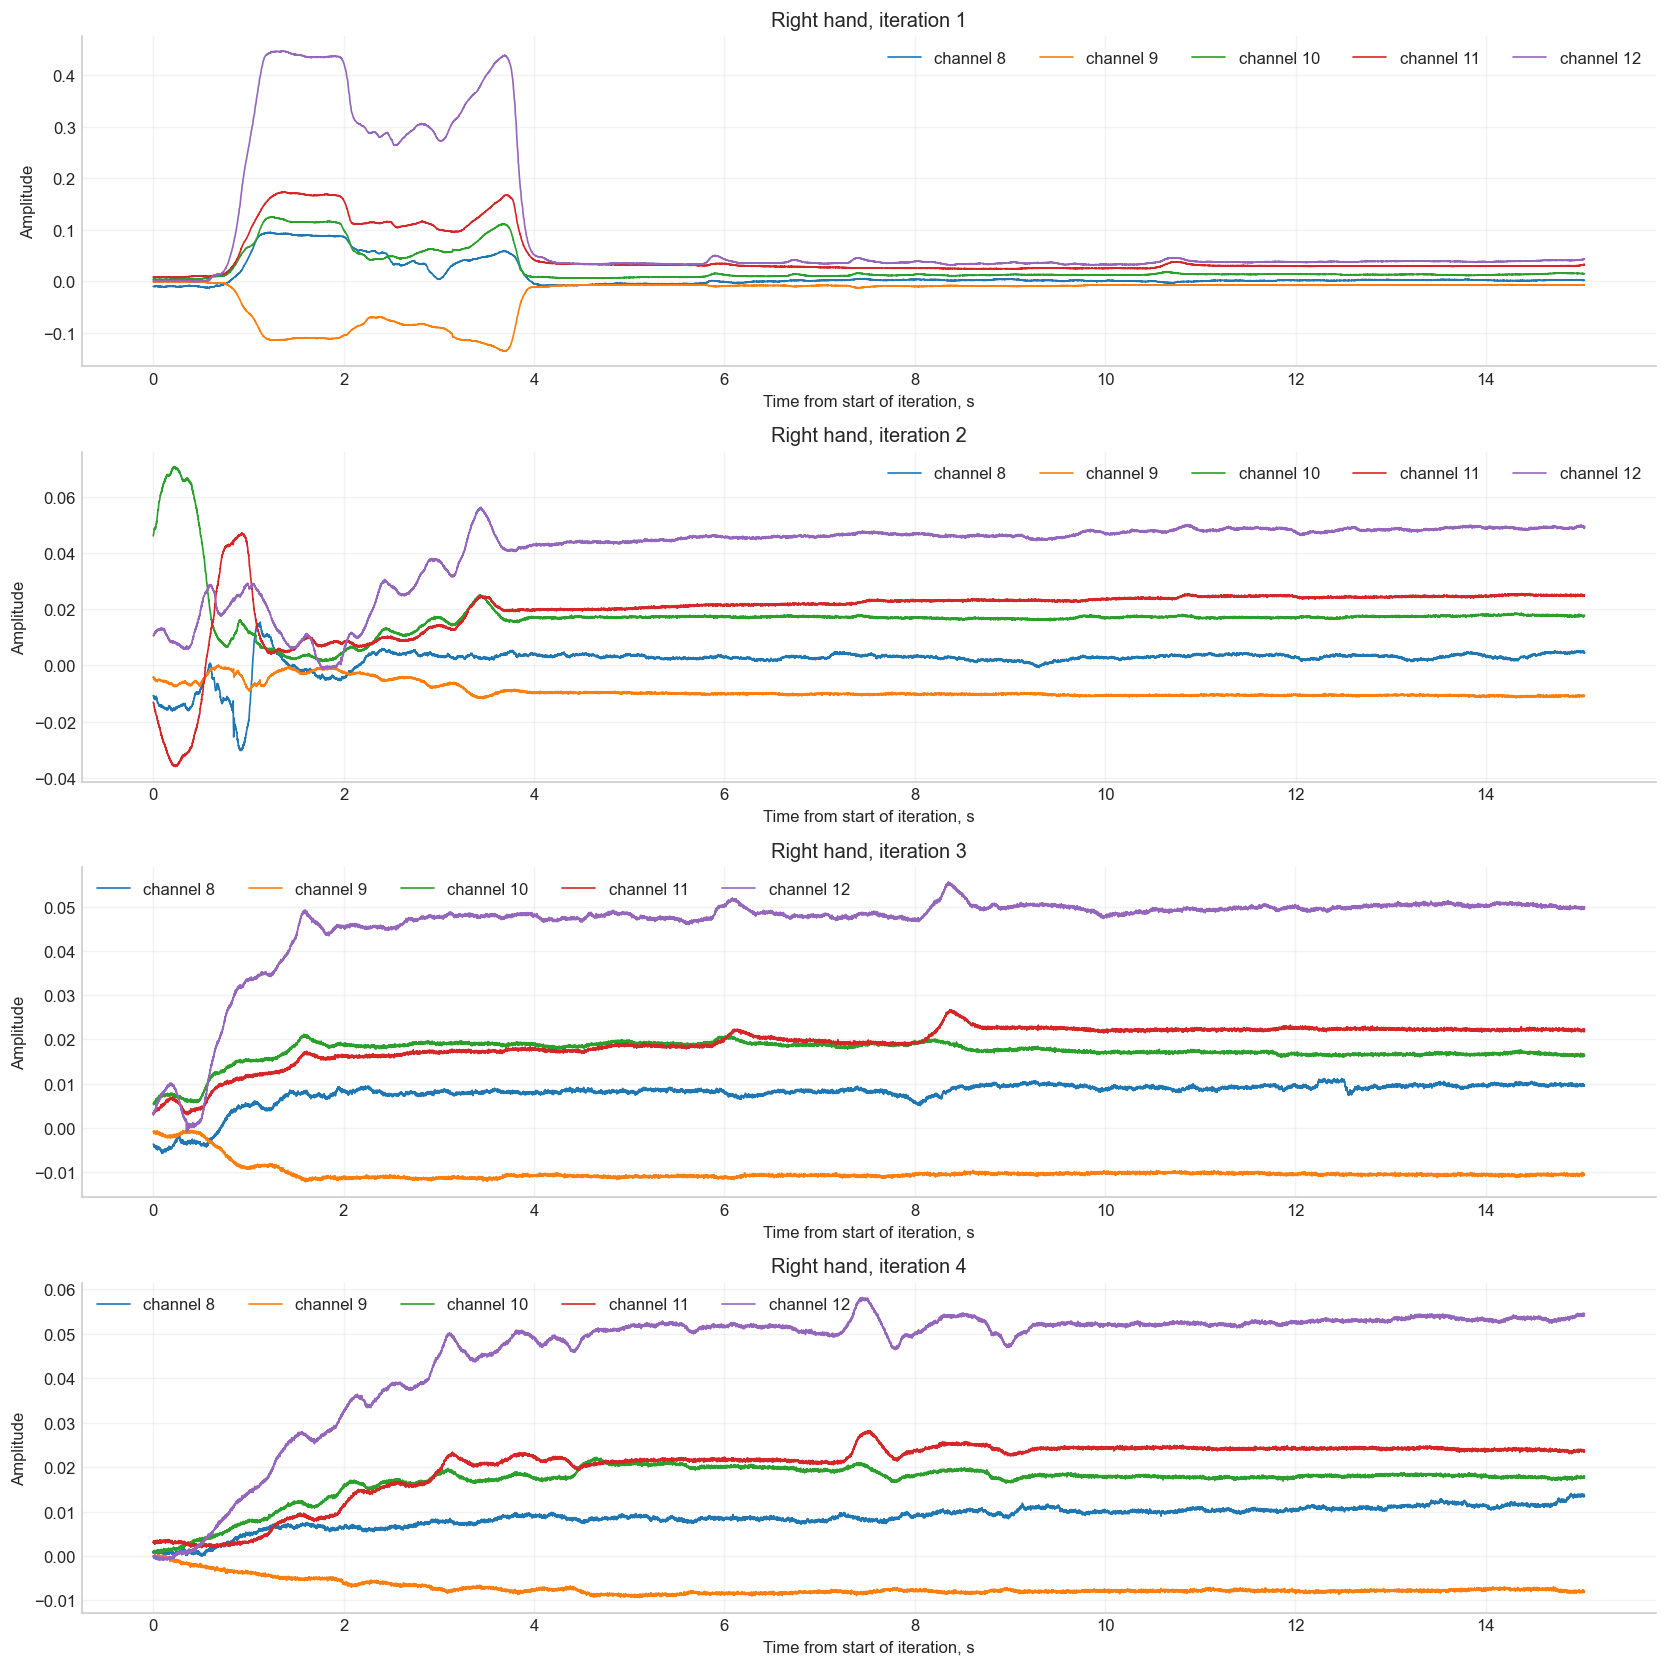

Patient - Left Hand - Cropped


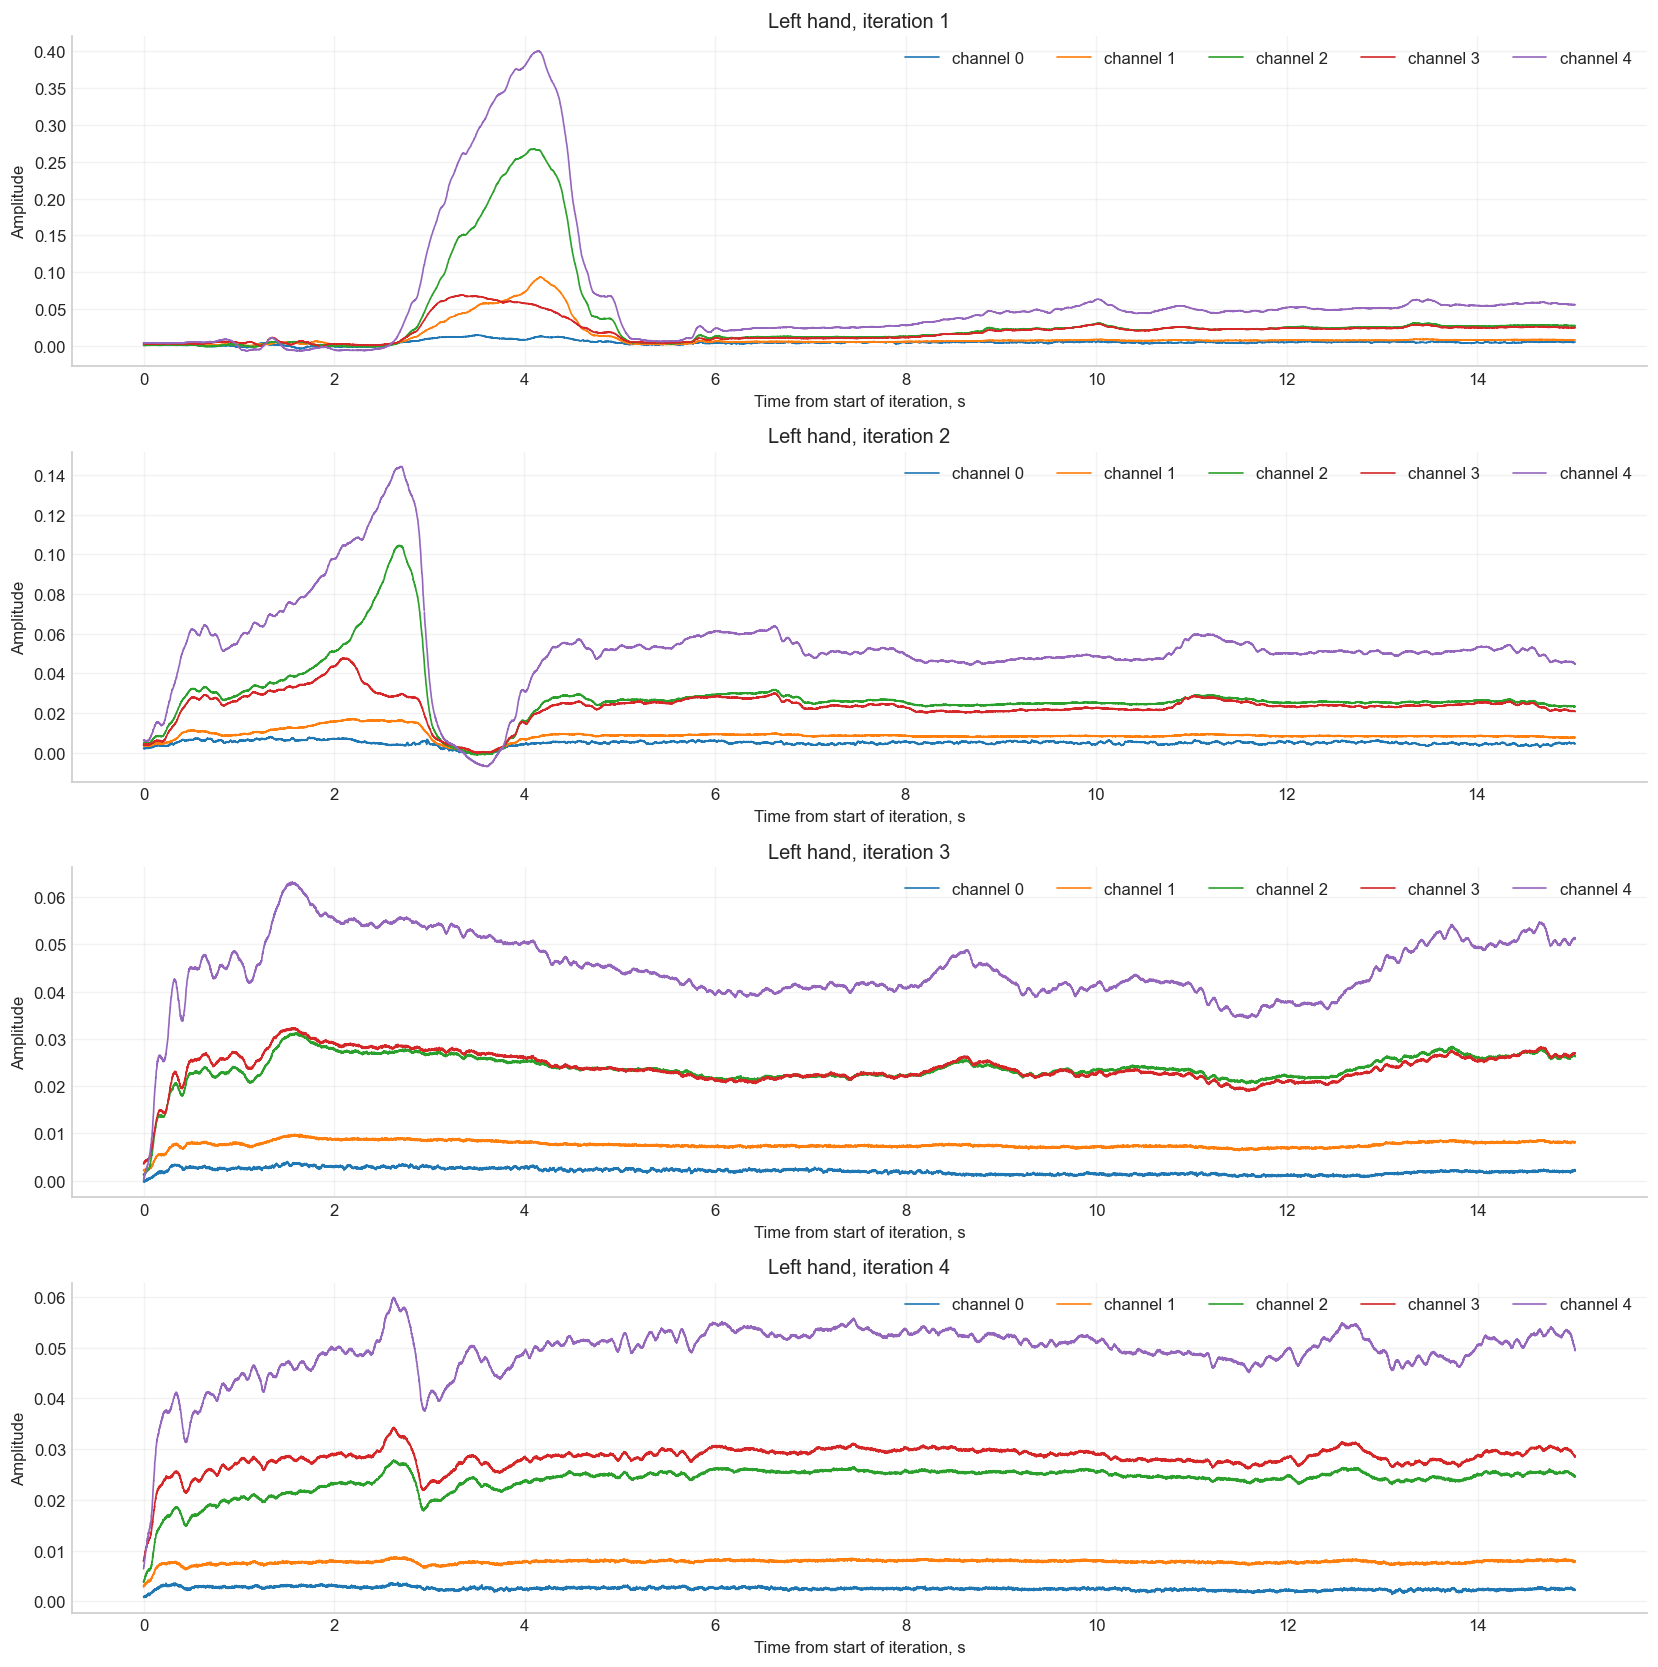

Patient - Right Hand - Cropped


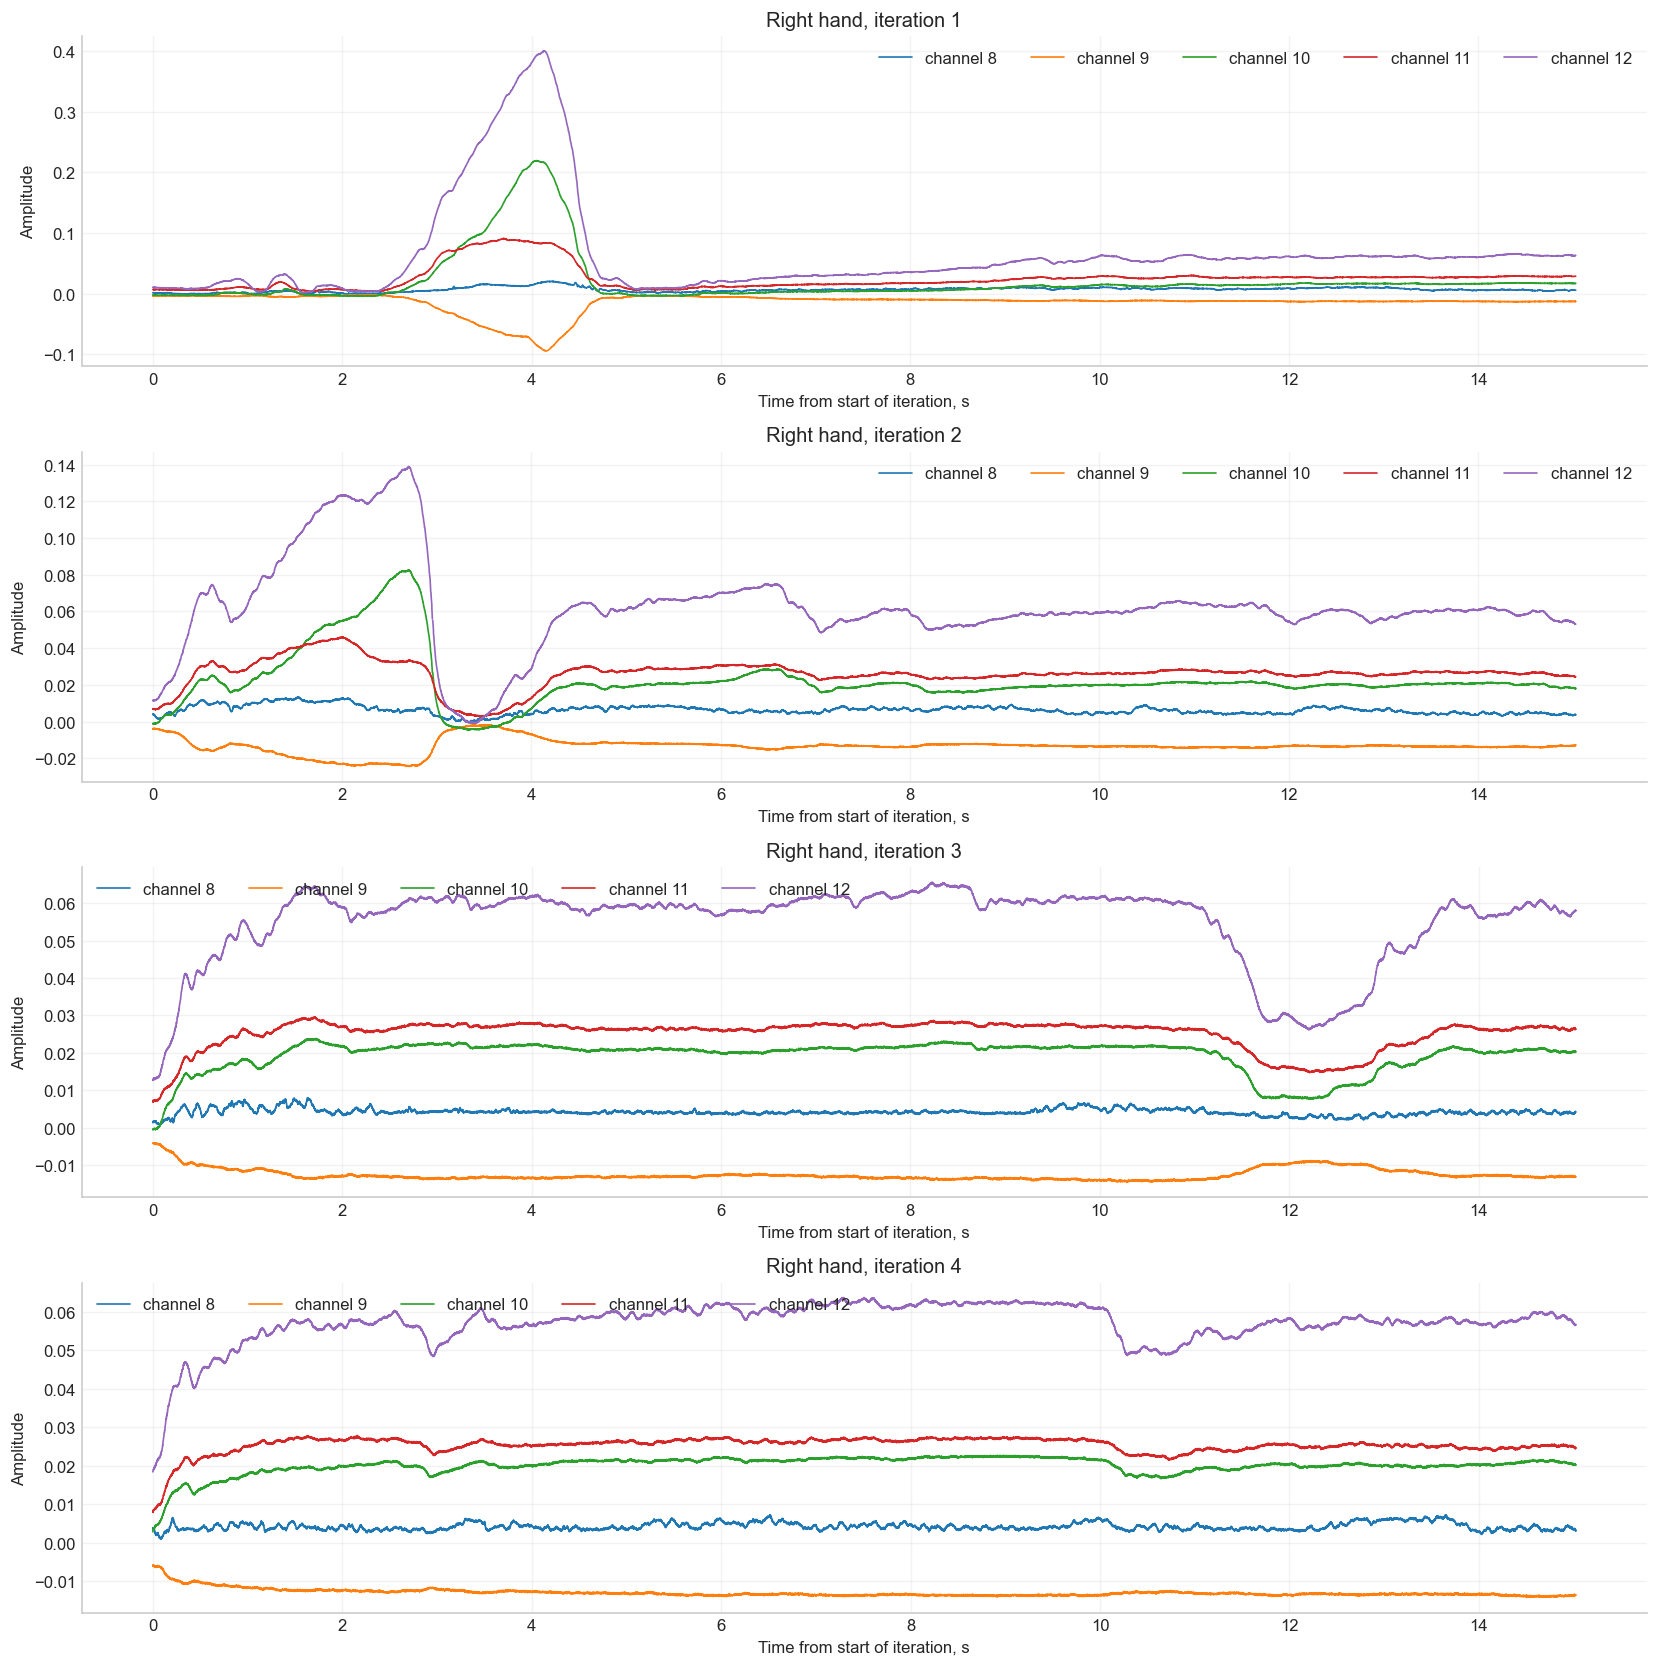

In [8]:
def crop_measurement(
    frame: pd.DataFrame,
    start_seconds: float,
    end_seconds: float,
    sampling_rate: float,
    participant: str,
) -> pd.DataFrame:
    start_index = int(start_seconds * sampling_rate)
    end_crop_samples = int(end_seconds * sampling_rate)

    cropped_iterations = []

    for iteration_number, iteration_frame in frame.groupby(
        "iteration",
        sort=True,
    ):
        required_samples = start_index + end_crop_samples

        if len(iteration_frame) <= required_samples:
            raise ValueError(
                f"{participant}, iteration {iteration_number}: "
                f"{len(iteration_frame)} samples are not enough to remove "
                f"{start_index} from the start and "
                f"{end_crop_samples} from the end"
            )

        end_index = (
            len(iteration_frame) - end_crop_samples
            if end_crop_samples
            else len(iteration_frame)
        )

        cropped_iteration = (
            iteration_frame
            .iloc[start_index:end_index]
            .copy()
            .reset_index(drop=True)
        )

        cropped_iteration["elapsed_seconds"] = (
            np.arange(len(cropped_iteration), dtype=float)
            / sampling_rate
        )

        cropped_iterations.append(cropped_iteration)

    return pd.concat(
        cropped_iterations,
        ignore_index=True,
    )

healthy_cropped = crop_measurement(healthy_frame, n_start, m_end, s, "Healthy")
patient_cropped = crop_measurement(patient_frame, n_start, m_end, s, "Patient")

for participant, frame in (("Healthy", healthy_cropped), ("Patient", patient_cropped)):
    for hand in ("left", "right"):
        print(f"{participant} - {hand.title()} Hand - Cropped")
        plot_hand(frame, hand=hand)

## 6. Representative hand signal extraction and duration equalization

Each representative hand signal is the arithmetic mean of its five channels. This is channel aggregation, not concatenation. Invalid values are rejected before spectral analysis. Both participants are truncated to the shorter cropped recording; no zero-padding is used.

In [9]:
def prepare_channels_for_analysis(
    frame: pd.DataFrame,
    participant: str,
) -> pd.DataFrame:
    prepared_iterations = []

    for iteration_number, iteration_frame in frame.groupby(
        "iteration",
        sort=True,
    ):
        prepared = iteration_frame.copy()

        values = prepared[CHANNEL_COLUMNS].replace(
            [np.inf, -np.inf],
            np.nan,
        )

        invalid_before = int(values.isna().sum().sum())

        if invalid_before:
            values = values.interpolate(
                method="linear",
                axis=0,
                limit_direction="both",
            )

        invalid_after = int(values.isna().sum().sum())

        if invalid_after:
            raise ValueError(
                f"{participant}, iteration {iteration_number}: "
                f"{invalid_after} invalid values remain"
            )

        prepared.loc[:, CHANNEL_COLUMNS] = values
        prepared_iterations.append(prepared)

    return pd.concat(
        prepared_iterations,
        ignore_index=True,
    )

def extract_hand_signals_by_iteration(
    frame: pd.DataFrame,
    participant: str,
) -> dict[int, dict[str, np.ndarray]]:
    hand_channels = {
        "Left": [f"channel_{channel}" for channel in LEFT_HAND_CHANNELS],
        "Right": [f"channel_{channel}" for channel in RIGHT_HAND_CHANNELS],
    }

    signals_by_iteration = {}

    for iteration_number, iteration_frame in frame.groupby(
        "iteration",
        sort=True,
    ):
        iteration_signals = {}

        for hand, columns in hand_channels.items():
            values = iteration_frame[columns].to_numpy(dtype=float)

            invalid_count = int((~np.isfinite(values)).sum())

            if invalid_count:
                raise ValueError(
                    f"{participant}, iteration {iteration_number}, "
                    f"{hand} Hand contains "
                    f"{invalid_count} invalid values"
                )

            iteration_signals[hand] = values.mean(axis=1)

        signals_by_iteration[int(iteration_number)] = iteration_signals

    return signals_by_iteration

def equalize_signal_lengths_by_iteration(
    healthy_signals: dict[int, dict[str, np.ndarray]],
    patient_signals: dict[int, dict[str, np.ndarray]],
    sampling_rate: float,
) -> tuple[
    dict[int, dict[str, np.ndarray]],
    dict[int, dict[str, np.ndarray]],
]:
    common_iterations = sorted(
        set(healthy_signals) & set(patient_signals)
    )

    if not common_iterations:
        raise ValueError("No common iterations found")

    healthy_equal = {}
    patient_equal = {}

    for iteration_number in common_iterations:
        healthy_equal[iteration_number] = {}
        patient_equal[iteration_number] = {}

        for hand in ("Left", "Right"):
            healthy_signal = healthy_signals[iteration_number][hand]
            patient_signal = patient_signals[iteration_number][hand]

            common_samples = min(
                len(healthy_signal),
                len(patient_signal),
            )

            if common_samples == 0:
                raise ValueError(
                    f"Iteration {iteration_number}, {hand}: "
                    "no samples remain"
                )

            healthy_equal[iteration_number][hand] = (
                healthy_signal[:common_samples].copy()
            )

            patient_equal[iteration_number][hand] = (
                patient_signal[:common_samples].copy()
            )

            print(
                f"Iteration {iteration_number}, {hand}: "
                f"{common_samples / sampling_rate:.3f} s"
            )

    return healthy_equal, patient_equal


healthy_analysis_frame = prepare_channels_for_analysis(healthy_cropped, "Healthy")
patient_analysis_frame = prepare_channels_for_analysis(patient_cropped, "Patient")
healthy_signals = extract_hand_signals_by_iteration(healthy_analysis_frame, "Healthy")
patient_signals = extract_hand_signals_by_iteration(patient_analysis_frame, "Patient")

for iteration_number, signals in healthy_signals.items():
    print(
        iteration_number,
        len(signals["Left"]),
        len(signals["Right"]),
    )

healthy_signals = extract_hand_signals_by_iteration(
    healthy_analysis_frame,
    "Healthy",
)

patient_signals = extract_hand_signals_by_iteration(
    patient_analysis_frame,
    "Patient",
)

healthy_equal, patient_equal = (
    equalize_signal_lengths_by_iteration(
        healthy_signals,
        patient_signals,
        s,
    )
)


1 15040 15040
2 15056 15056
3 15047 15047
4 15051 15051
Iteration 1, Left: 15.040 s
Iteration 1, Right: 15.040 s
Iteration 2, Left: 15.043 s
Iteration 2, Right: 15.043 s
Iteration 3, Left: 15.042 s
Iteration 3, Right: 15.042 s
Iteration 4, Left: 15.038 s
Iteration 4, Right: 15.038 s


## 7. Representative signal comparison

Healthy and Patient signals use the same time axis. Each hand uses shared y-axis limits across participants to keep the amplitude comparison visually honest.

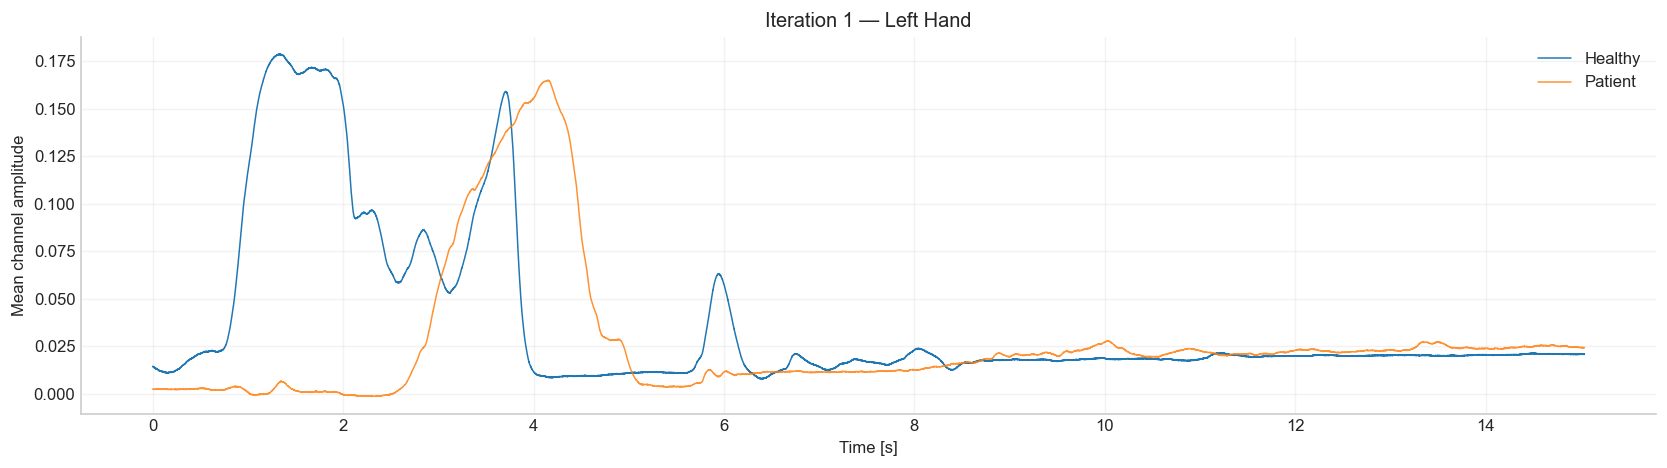

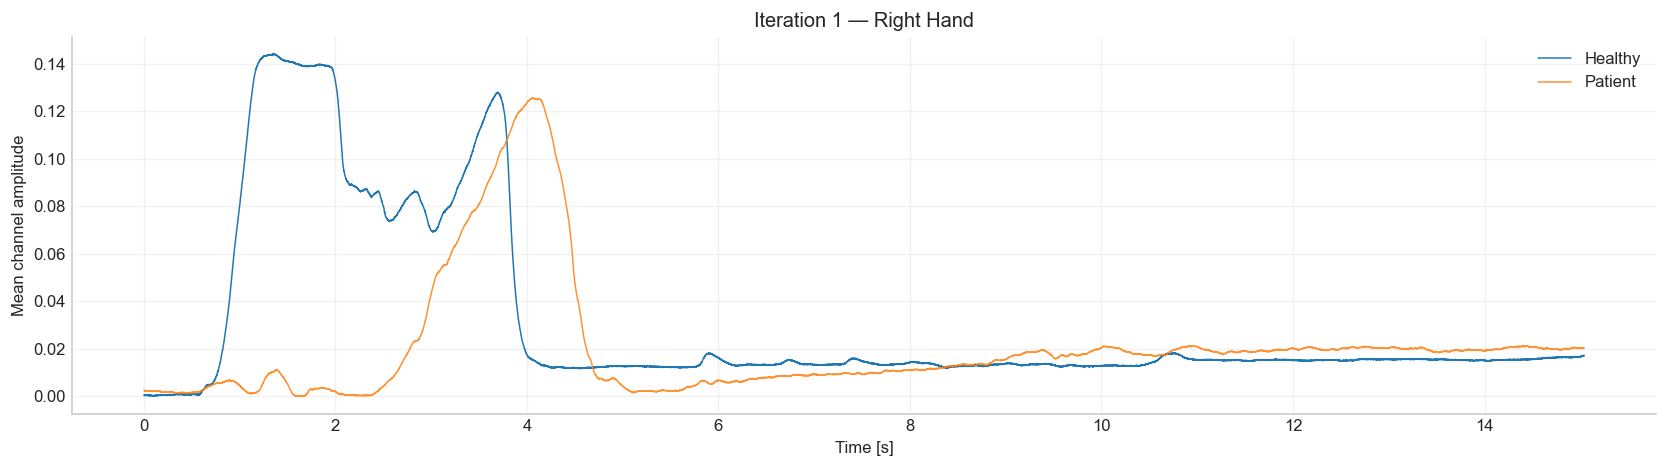

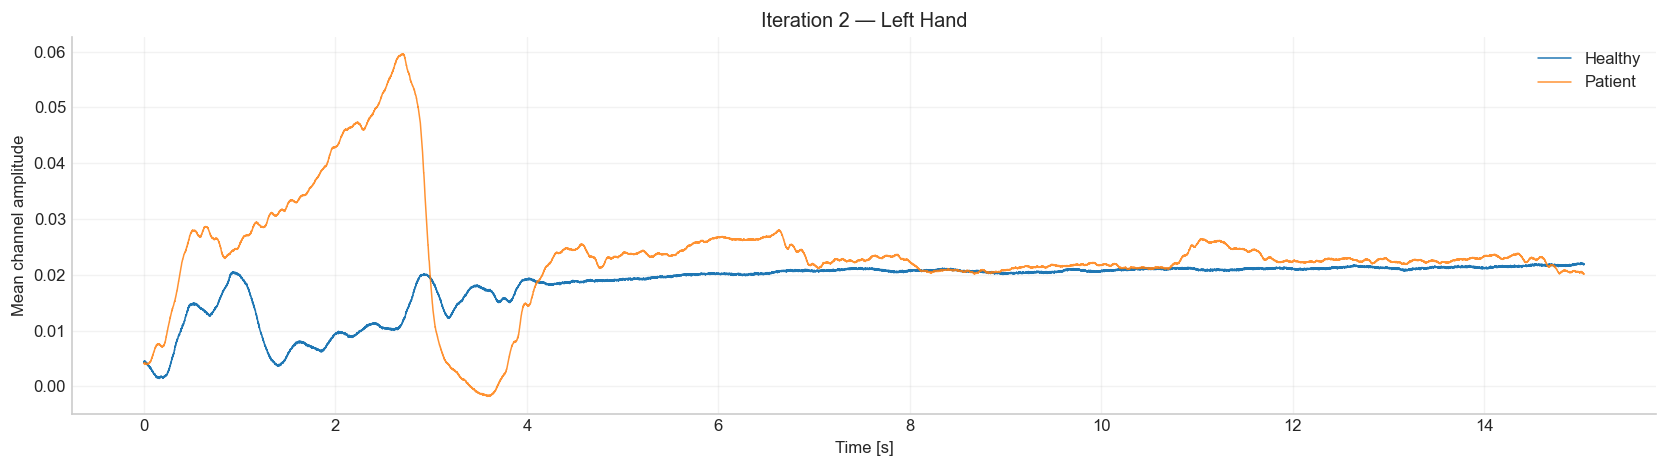

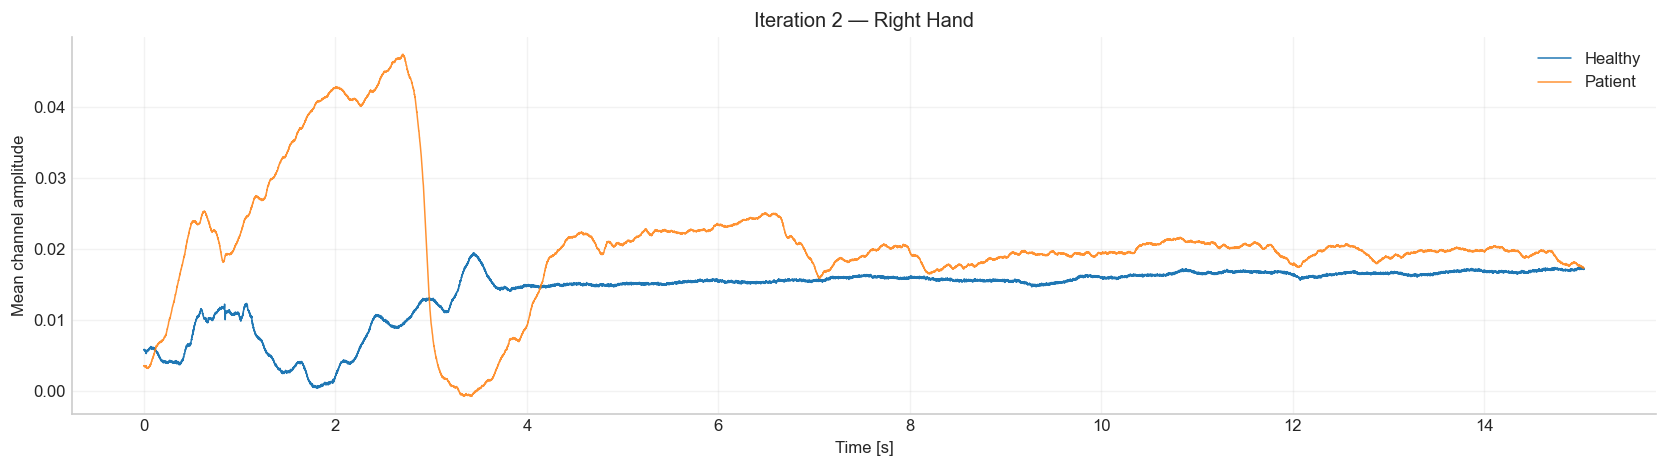

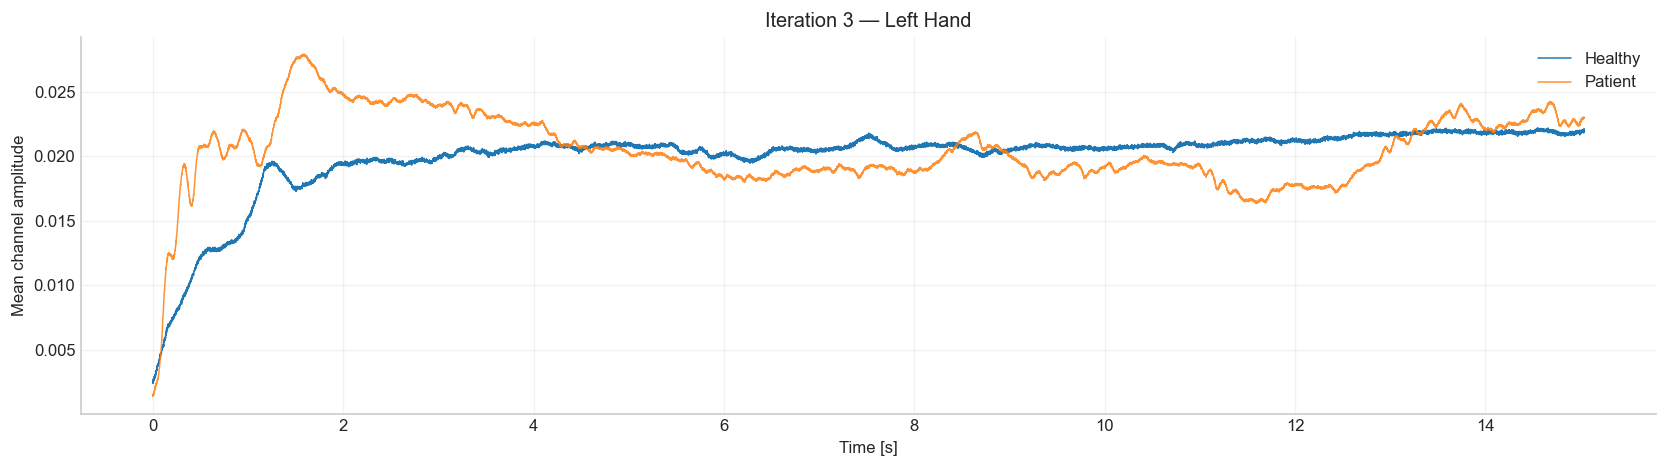

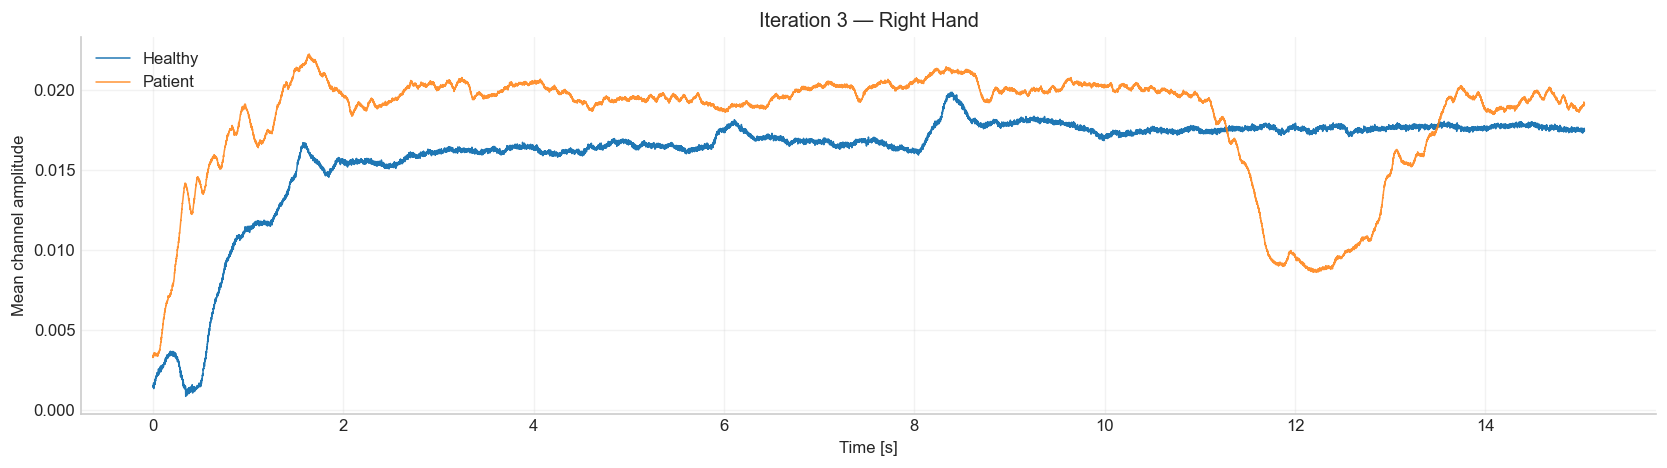

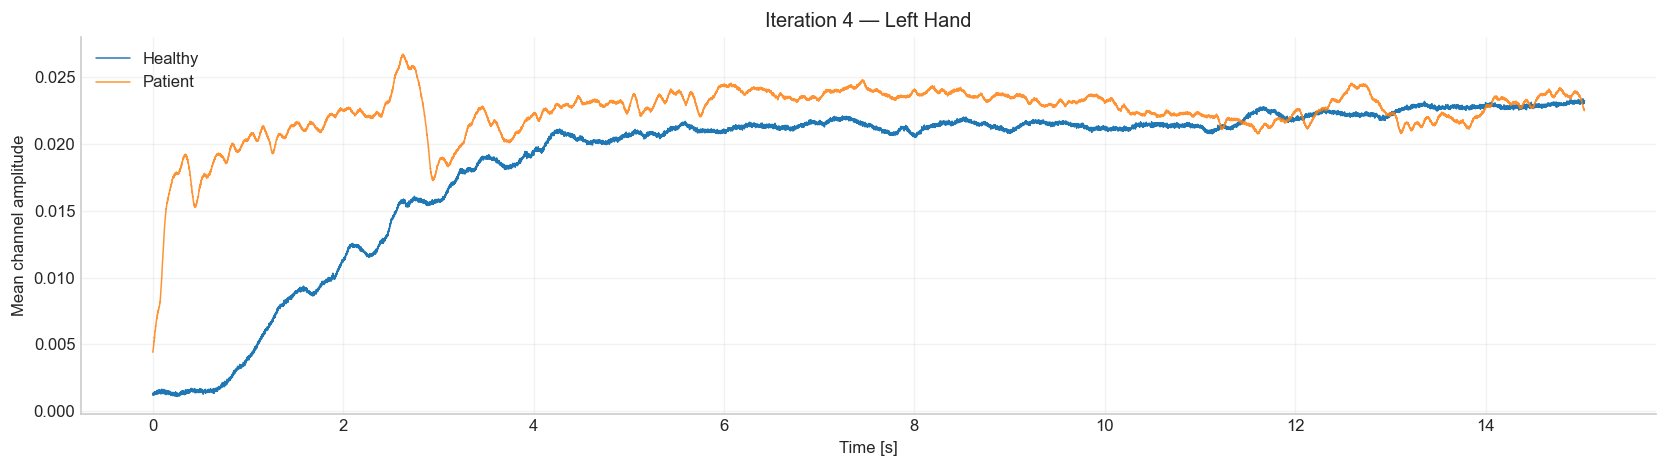

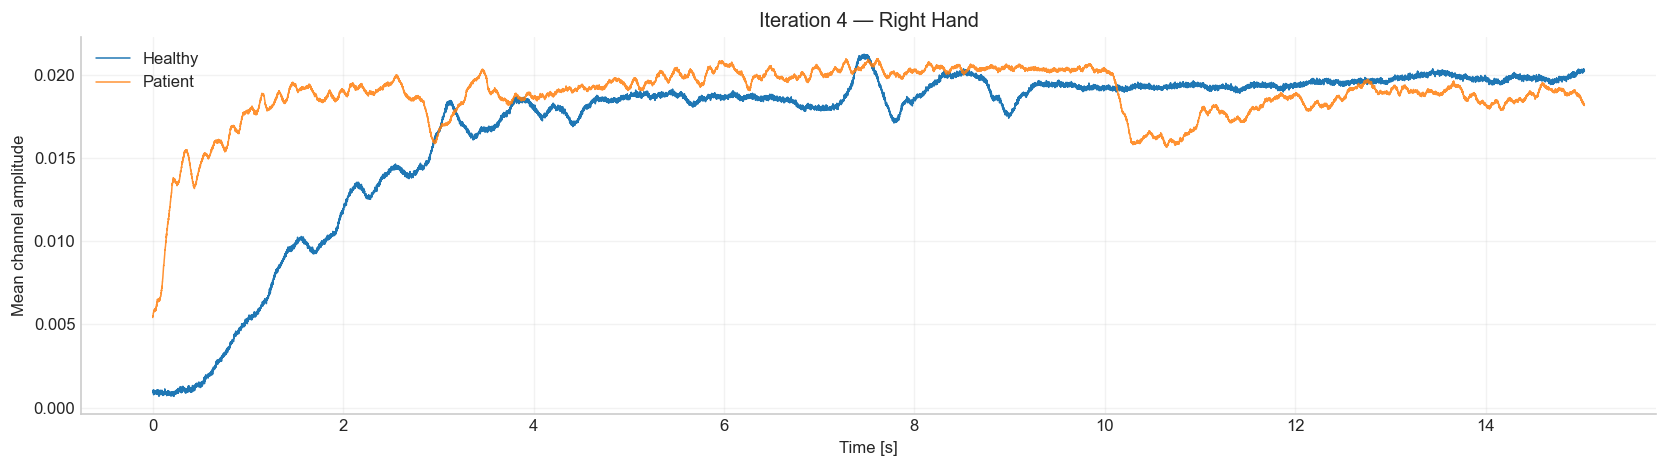

In [10]:
for iteration_number in sorted(healthy_equal):
    common_samples = len(
        healthy_equal[iteration_number]["Left"]
    )

    time_seconds = (
        np.arange(common_samples, dtype=float) / s
    )

    for hand in ("Left", "Right"):
        plt.figure(figsize=(14, 4))

        plt.plot(
            time_seconds,
            healthy_equal[iteration_number][hand],
            label="Healthy",
            linewidth=0.9,
        )

        plt.plot(
            time_seconds,
            patient_equal[iteration_number][hand],
            label="Patient",
            linewidth=0.9,
            alpha=0.85,
        )

        plt.title(
            f"Iteration {iteration_number} — {hand} Hand"
        )
        plt.xlabel("Time [s]")
        plt.ylabel("Mean channel amplitude")
        plt.legend()
        plt.grid(alpha=0.25)
        plt.tight_layout()
        plt.show()

In [11]:
print(healthy_equal[1].keys())

dict_keys(['Left', 'Right'])


In [12]:
# Select which measurement iteration should be used by sections 8+.
# Use a zero-based index: 0 -> first iteration, 1 -> second iteration, etc.
SELECTED_ITERATION_INDEX = 2

available_iterations = sorted(set(healthy_equal) & set(patient_equal))
if not available_iterations:
    raise ValueError("No common iterations are available for analysis")
if not 0 <= SELECTED_ITERATION_INDEX < len(available_iterations):
    raise IndexError(
        f"SELECTED_ITERATION_INDEX must be between 0 and {len(available_iterations) - 1}"
    )

selected_iteration = available_iterations[SELECTED_ITERATION_INDEX]
healthy_selected = healthy_equal[selected_iteration]
patient_selected = patient_equal[selected_iteration]

healthy_left_signal = healthy_selected["Left"]
healthy_right_signal = healthy_selected["Right"]
patient_left_signal = patient_selected["Left"]
patient_right_signal = patient_selected["Right"]

print(
    f"Selected iteration index: {SELECTED_ITERATION_INDEX} "
    f"(iteration key: {selected_iteration})"
)


Selected iteration index: 2 (iteration key: 3)


## 8. Sequential non-overlapping Fourier analysis

For each 3, 5, and 10 second block, the mean is removed with `detrend`, then a Hann window is applied. The one-sided amplitude is normalized as

\[
A_k = \frac{|X_k|}{N\,G_c},
\]

where $N$ is the block length and $G_c$ is the Hann coherent gain (the mean of the window). Interior one-sided bins are doubled; DC and the Nyquist bin are not. DC is excluded from all metrics. Metrics use the same predefined positive-frequency range up to `MAX_FREQUENCY_HZ` for every signal, avoiding domination by out-of-band sensor noise. Only complete contiguous blocks are analyzed, without overlap or padding.

In [13]:
def preprocess_fft_block(block: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    values = np.asarray(block, dtype=float)
    if values.ndim != 1 or values.size < 2:
        raise ValueError("FFT block must be a one-dimensional array with at least two samples")
    if not np.isfinite(values).all():
        raise ValueError("FFT block contains NaN or infinite values")
    window = get_window("hann", values.size, fftbins=True)
    return detrend(values, type="constant") * window, window


def compute_one_sided_spectrum(
    block: np.ndarray,
    sampling_rate: float,
) -> tuple[np.ndarray, np.ndarray]:
    prepared, window = preprocess_fft_block(block)
    sample_count = prepared.size
    coherent_gain = window.mean()
    if coherent_gain <= 0:
        raise ValueError("Hann coherent gain must be positive")

    frequencies = rfftfreq(sample_count, d=1 / sampling_rate)
    amplitudes = np.abs(rfft(prepared)) / (sample_count * coherent_gain)
    if sample_count % 2 == 0:
        amplitudes[1:-1] *= 2
    else:
        amplitudes[1:] *= 2
    return frequencies, amplitudes


def extract_spectral_metrics(
    frequencies: np.ndarray,
    amplitudes: np.ndarray,
    maximum_frequency_hz: Optional[float] = None,
) -> dict[str, float]:
    analysis_mask = frequencies > 0
    if maximum_frequency_hz is not None:
        analysis_mask &= frequencies <= maximum_frequency_hz
    analysis_frequencies = frequencies[analysis_mask]
    analysis_amplitudes = amplitudes[analysis_mask]
    if analysis_frequencies.size == 0:
        raise ValueError("Spectrum does not contain frequencies in the analysis range")

    amplitude_sum = analysis_amplitudes.sum()
    weighted_mean_frequency = (
        float(np.sum(analysis_frequencies * analysis_amplitudes) / amplitude_sum)
        if amplitude_sum > 0
        else np.nan
    )
    return {
        "mean_spectral_amplitude": float(analysis_amplitudes.mean()),
        "dominant_frequency_hz": float(
            analysis_frequencies[np.argmax(analysis_amplitudes)]
        ),
        "weighted_mean_frequency_hz": weighted_mean_frequency,
    }


def analyze_windowed_fft(
    signal: np.ndarray,
    participant: str,
    hand: str,
    window_seconds: float,
    sampling_rate: float,
    maximum_frequency_hz: Optional[float] = None,
) -> pd.DataFrame:
    values = np.asarray(signal, dtype=float)
    if not np.isfinite(values).all():
        raise ValueError(f"{participant} {hand}: signal contains invalid values")

    window_samples = int(window_seconds * sampling_rate)
    if window_samples <= 1:
        raise ValueError("FFT window must contain at least two samples")
    number_of_windows = len(values) // window_samples
    if number_of_windows == 0:
        raise ValueError(
            f"{participant} {hand}: {window_seconds}s window is longer than the signal"
        )

    usable_samples = number_of_windows * window_samples
    rows = []
    for block_index, start in enumerate(range(0, usable_samples, window_samples)):
        block = values[start:start + window_samples]
        frequencies, amplitudes = compute_one_sided_spectrum(block, sampling_rate)
        metrics = extract_spectral_metrics(
            frequencies,
            amplitudes,
            maximum_frequency_hz,
        )
        start_time = start / sampling_rate
        end_time = (start + window_samples) / sampling_rate
        rows.append({
            "participant": participant,
            "hand": hand,
            "window_seconds": window_seconds,
            "block_index": block_index,
            "start_time_seconds": start_time,
            "center_time_seconds": (start_time + end_time) / 2,
            "end_time_seconds": end_time,
            **metrics,
        })
    return pd.DataFrame(rows)


signal_map = {
    ("Healthy", "Left"): healthy_left_signal,
    ("Healthy", "Right"): healthy_right_signal,
    ("Patient", "Left"): patient_left_signal,
    ("Patient", "Right"): patient_right_signal,
}

fft_results = pd.concat(
    [
        analyze_windowed_fft(
            signal,
            participant,
            hand,
            window_seconds,
            s,
            MAX_FREQUENCY_HZ,
        )
        for window_seconds in window_lengths
        for (participant, hand), signal in signal_map.items()
    ],
    ignore_index=True,
)

window_count_check = (
    fft_results.groupby(["window_seconds", "participant", "hand"])
    .size()
    .rename("complete_windows")
    .unstack(["participant", "hand"])
)
display(window_count_check)
display(fft_results.head())

participant    Healthy       Patient      
hand              Left Right    Left Right
window_seconds                            
3                    5     5       5     5
5                    3     3       3     3
10                   1     1       1     1

,participant,hand,window_seconds,block_index,start_time_seconds,center_time_seconds,end_time_seconds,mean_spectral_amplitude,dominant_frequency_hz,weighted_mean_frequency_hz
0,Healthy,Left,3,0,0.0,1.5,3.0,0.000100,0.333333,1.992257
1,Healthy,Left,3,1,3.0,4.5,6.0,0.000016,0.333333,5.678453
2,Healthy,Left,3,2,6.0,7.5,9.0,0.000025,0.333333,3.605432
3,Healthy,Left,3,3,9.0,10.5,12.0,0.000014,0.333333,6.400836
4,Healthy,Left,3,4,12.0,13.5,15.0,0.000010,0.333333,6.787650


## 9. FFT metric trends over time

Each point represents one complete non-overlapping block and is placed at the block center. Healthy and Patient traces share each axis and therefore share its scale.

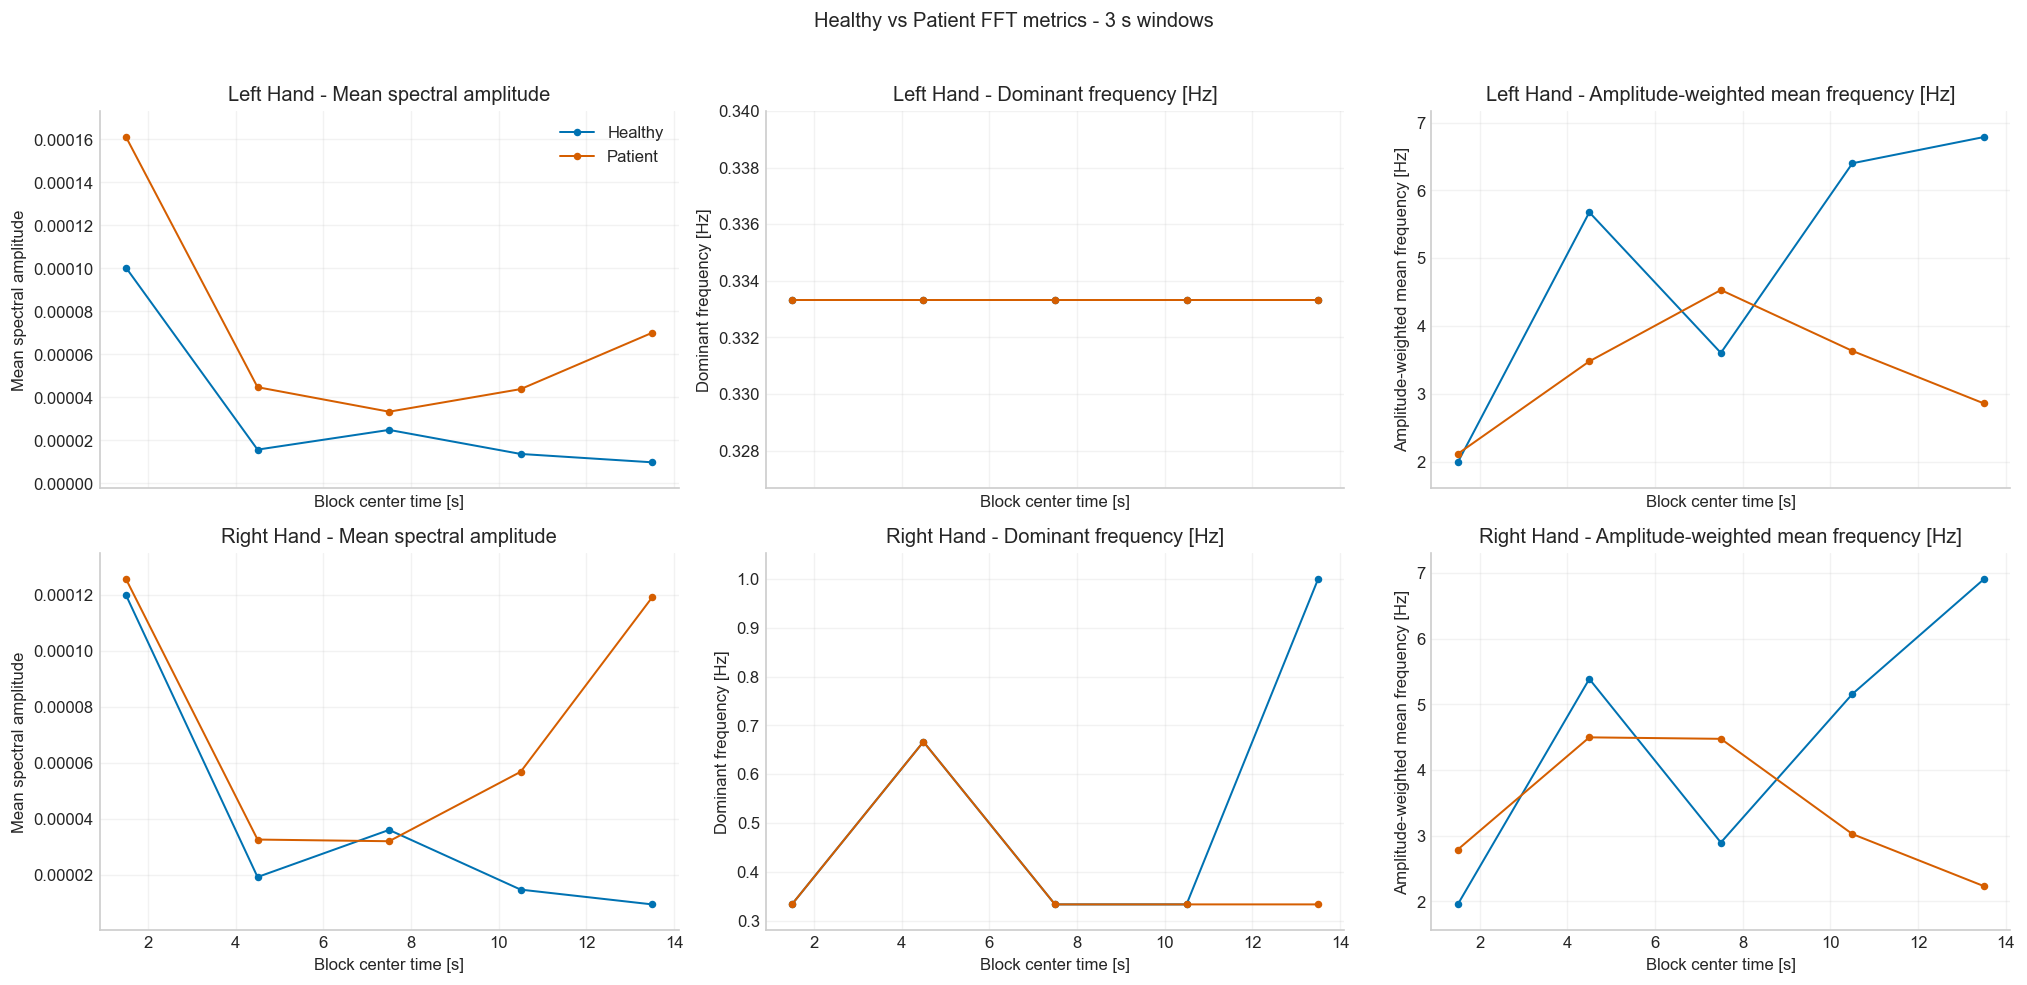

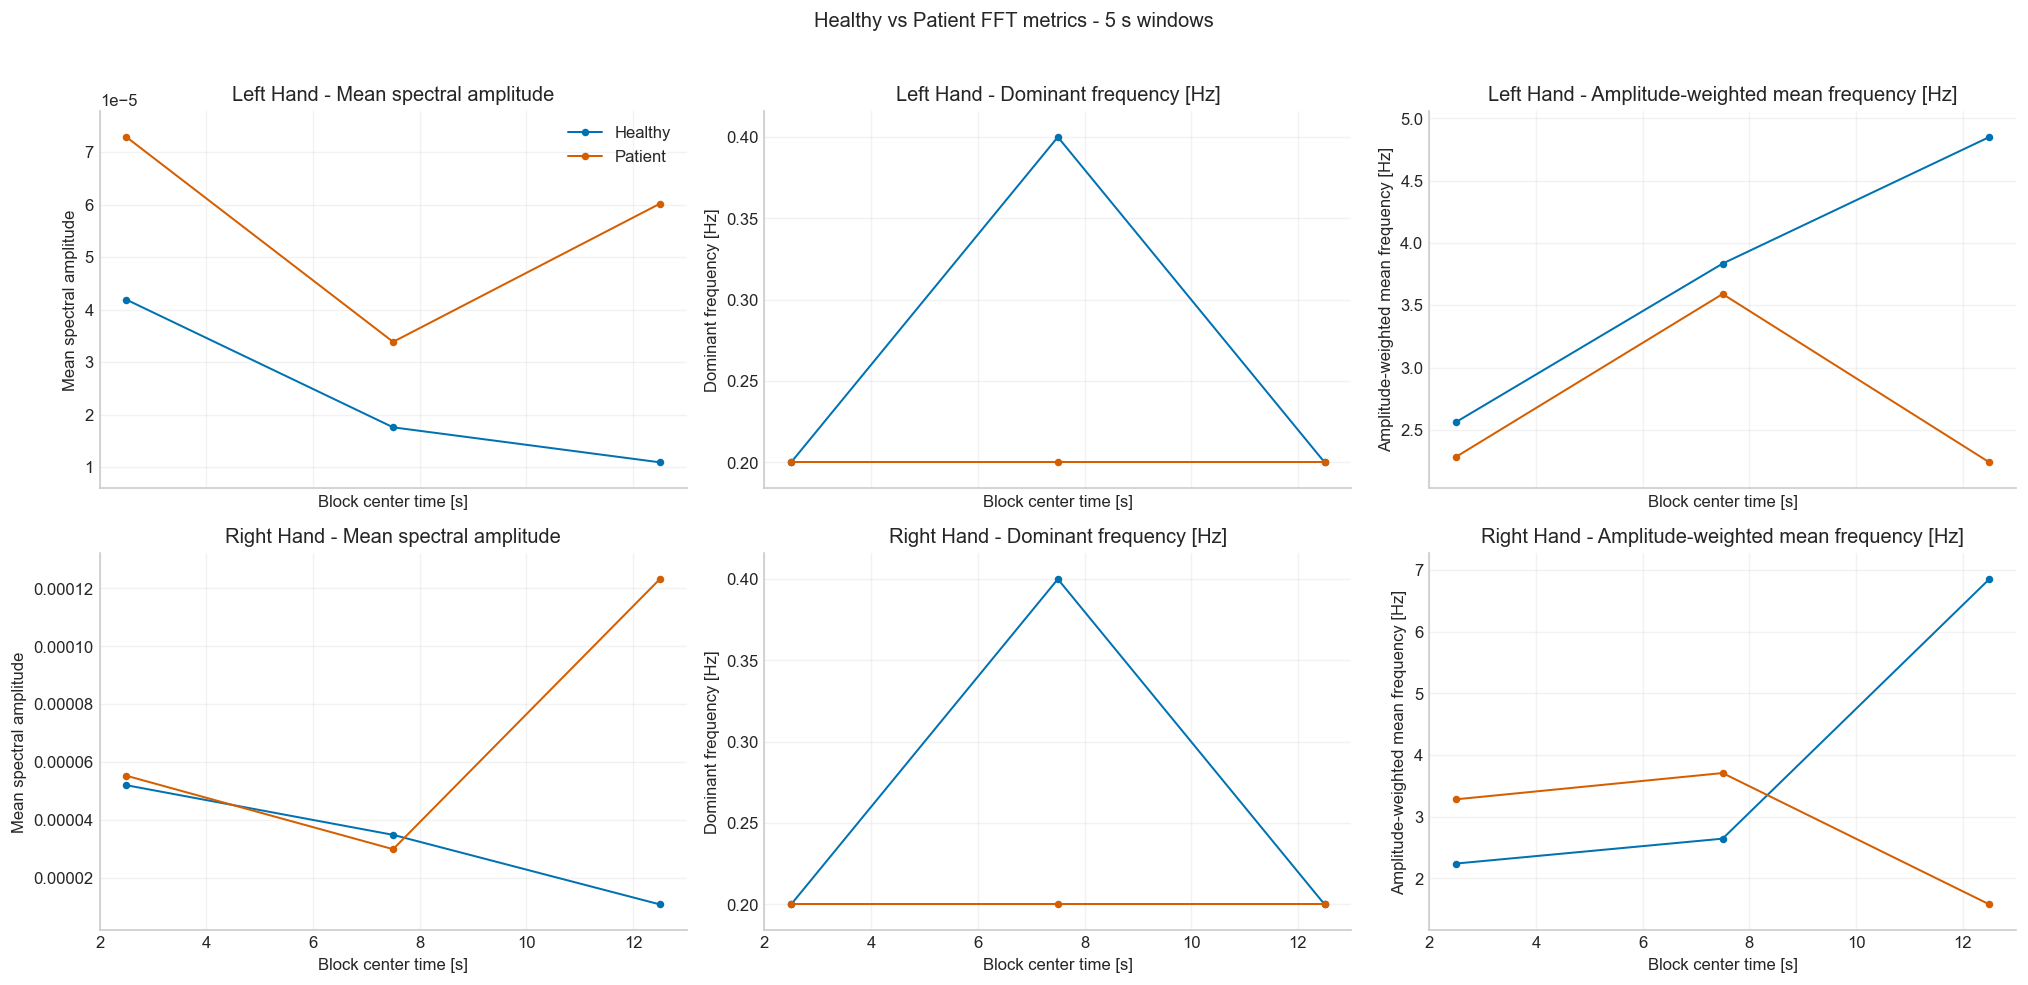

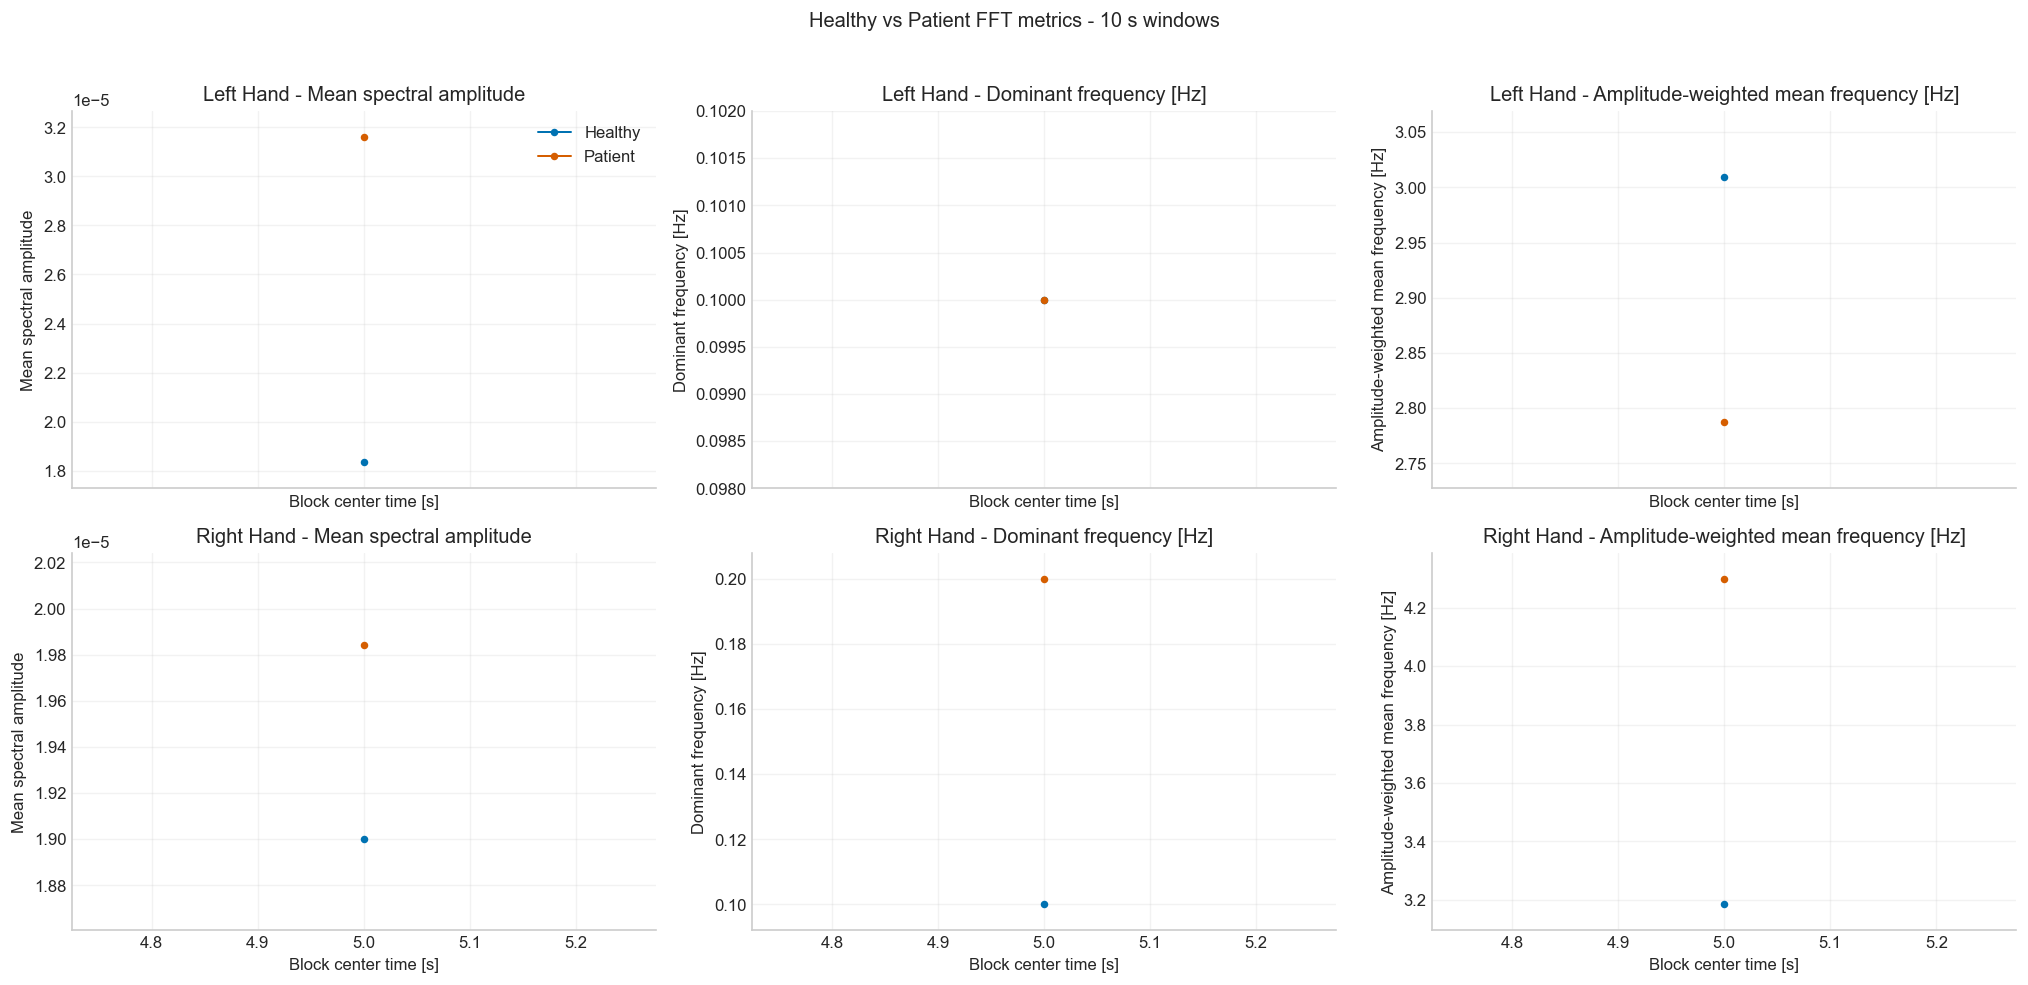

In [14]:
FFT_METRICS = {
    "mean_spectral_amplitude": "Mean spectral amplitude",
    "dominant_frequency_hz": "Dominant frequency [Hz]",
    "weighted_mean_frequency_hz": "Amplitude-weighted mean frequency [Hz]",
}


def plot_fft_metric_trends(results: pd.DataFrame, window_seconds: float) -> None:
    subset = results[results["window_seconds"] == window_seconds]
    fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharex=True)
    colors = {"Healthy": "#0072B2", "Patient": "#D55E00"}

    for row_index, hand in enumerate(("Left", "Right")):
        for column_index, (metric, label) in enumerate(FFT_METRICS.items()):
            ax = axes[row_index, column_index]
            hand_metric = subset[subset["hand"] == hand]
            for participant in ("Healthy", "Patient"):
                participant_data = hand_metric[
                    hand_metric["participant"] == participant
                ]
                ax.plot(
                    participant_data["center_time_seconds"],
                    participant_data[metric],
                    marker="o",
                    markersize=3.5,
                    linewidth=1.2,
                    color=colors[participant],
                    label=participant,
                )
            values = hand_metric[metric].to_numpy(dtype=float)
            finite_values = values[np.isfinite(values)]
            if finite_values.size:
                lower, upper = finite_values.min(), finite_values.max()
                margin = max((upper - lower) * 0.08, abs(upper) * 0.02, 1e-12)
                ax.set_ylim(lower - margin, upper + margin)
            # ax.set_xlim(0, common_time[-1])
            analysis_duration_seconds = min(
                len(signal) for signal in signal_map.values()
            ) / s
            ax.set_title(f"{hand} Hand - {label}")
            ax.set_xlabel("Block center time [s]")
            ax.set_ylabel(label)
            ax.grid(alpha=0.25)
            if row_index == 0 and column_index == 0:
                ax.legend()

    fig.suptitle(f"Healthy vs Patient FFT metrics - {window_seconds:g} s windows", y=1.02)
    fig.tight_layout()
    plt.show()


for current_window_seconds in window_lengths:
    plot_fft_metric_trends(fft_results, current_window_seconds)

## 10. Shared-scale spectrogram comparison

All four spectrograms use the same 2 second Hann segments, 50% overlap, sampling rate, frequency range, time range, and color normalization. Power spectral density is converted to decibels using $10\log_{10}(P + \epsilon)$.

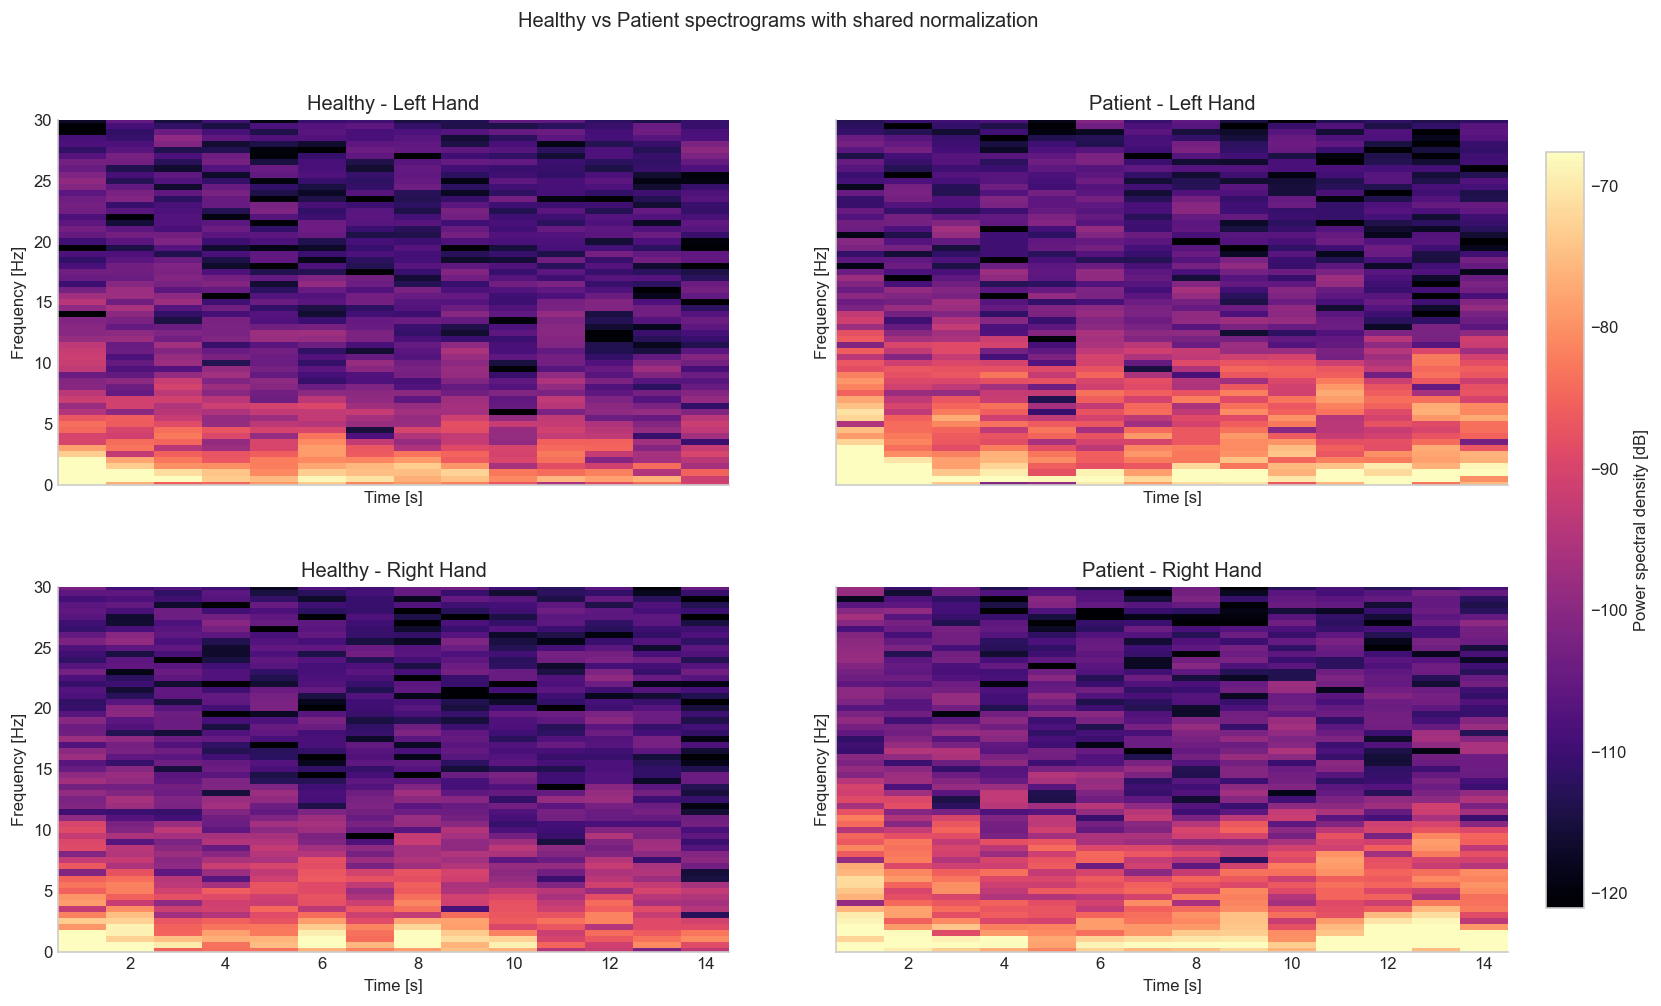

In [15]:
def compute_spectrogram_db(
    signal: np.ndarray,
    sampling_rate: float,
    window_seconds: float,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    values = np.asarray(signal, dtype=float)
    if not np.isfinite(values).all():
        raise ValueError("Spectrogram signal contains NaN or infinite values")
    nperseg = int(window_seconds * sampling_rate)
    if nperseg <= 1 or nperseg > values.size:
        raise ValueError("Invalid spectrogram segment length")
    frequencies, times, power = spectrogram(
        values,
        fs=sampling_rate,
        window="hann",
        nperseg=nperseg,
        noverlap=nperseg // 2,
        detrend="constant",
        scaling="density",
        mode="psd",
    )
    power_db = 10 * np.log10(power + np.finfo(float).eps)
    return frequencies, times, power_db


spectrogram_results = {
    key: compute_spectrogram_db(signal, s, spec_window)
    for key, signal in signal_map.items()
}
visible_values = []
for frequencies, _, power_db in spectrogram_results.values():
    visible_values.append(power_db[frequencies <= MAX_FREQUENCY_HZ].ravel())
all_visible_values = np.concatenate(visible_values)
vmin, vmax = np.quantile(all_visible_values, [0.02, 0.98])

fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharex=True, sharey=True)
image = None
for row_index, hand in enumerate(("Left", "Right")):
    for column_index, participant in enumerate(("Healthy", "Patient")):
        frequencies, times, power_db = spectrogram_results[(participant, hand)]
        frequency_mask = frequencies <= MAX_FREQUENCY_HZ
        image = axes[row_index, column_index].pcolormesh(
            times,
            frequencies[frequency_mask],
            power_db[frequency_mask],
            shading="auto",
            cmap="magma",
            vmin=vmin,
            vmax=vmax,
        )
        axes[row_index, column_index].set_title(f"{participant} - {hand} Hand")
        # axes[row_index, column_index].set_xlim(0, common_time[-1])
        analysis_duration_seconds = min(
            len(signal) for signal in signal_map.values()
        ) / s
        axes[row_index, column_index].set_ylim(0, MAX_FREQUENCY_HZ)
        axes[row_index, column_index].set_xlabel("Time [s]")
        axes[row_index, column_index].set_ylabel("Frequency [Hz]")

fig.subplots_adjust(right=0.88, hspace=0.28, wspace=0.16)
colorbar_axis = fig.add_axes([0.90, 0.15, 0.02, 0.70])
fig.colorbar(image, cax=colorbar_axis, label="Power spectral density [dB]")
fig.suptitle("Healthy vs Patient spectrograms with shared normalization", y=0.98)
plt.show()

## 11. Numerical summaries

The first table summarizes the distribution across complete FFT blocks. The second table reports Patient minus Healthy for each hand and window size; positive values mean a higher Patient average.

In [16]:
metric_columns = list(FFT_METRICS)
summary_statistics = (
    fft_results.groupby(["participant", "hand", "window_seconds"])[metric_columns]
    .agg(["mean", "std", "median", "min", "max", "count"])
    .sort_index()
)

group_means = (
    fft_results.groupby(["participant", "hand", "window_seconds"])[metric_columns]
    .mean()
    .reset_index()
)
healthy_means = group_means[group_means["participant"] == "Healthy"].drop(
    columns="participant"
)
patient_means = group_means[group_means["participant"] == "Patient"].drop(
    columns="participant"
)
patient_minus_healthy = patient_means.merge(
    healthy_means,
    on=["hand", "window_seconds"],
    suffixes=("_patient", "_healthy"),
)
for metric in metric_columns:
    patient_minus_healthy[f"{metric}_patient_minus_healthy"] = (
        patient_minus_healthy[f"{metric}_patient"]
        - patient_minus_healthy[f"{metric}_healthy"]
    )
patient_minus_healthy = patient_minus_healthy[
    ["hand", "window_seconds"]
    + [f"{metric}_patient_minus_healthy" for metric in metric_columns]
].sort_values(["hand", "window_seconds"])

display(summary_statistics)
display(patient_minus_healthy)

mean_spectral_amplitude                      \
                                                    mean       std    median   
participant hand  window_seconds                                               
Healthy     Left  3                             0.000033  0.000038  0.000016   
                  5                             0.000023  0.000016  0.000018   
                  10                            0.000018       NaN  0.000018   
            Right 3                             0.000040  0.000046  0.000019   
                  5                             0.000033  0.000021  0.000035   
                  10                            0.000019       NaN  0.000019   
Patient     Left  3                             0.000071  0.000052  0.000045   
                  5                             0.000056  0.000020  0.000060   
                  10                            0.000032       NaN  0.000032   
            Right 3                             0.000073  0.000046  0.000057   
                  5                             0.000069  0.000048  0.000055   
                  10                            0.000020       NaN  0.000020   

                                                            \
                                       min       max count   
participant hand  window_seconds                             
Healthy     Left  3               0.000010  0.000100     5   
                  5               0.000011  0.000042     3   
                  10              0.000018  0.000018     1   
            Right 3               0.000010  0.000120     5   
                  5               0.000011  0.000052     3   
                  10              0.000019  0.000019     1   
Patient     Left  3               0.000033  0.000161     5   
                  5               0.000034  0.000073     3   
                  10              0.000032  0.000032     1   
            Right 3               0.000032  0.000126     5   
                  5               0.000030  0.000123     3   
                  10              0.000020  0.000020     1   

                                 dominant_frequency_hz                      \
                                                  mean       std    median   
participant hand  window_seconds                                             
Healthy     Left  3                           0.333333  0.000000  0.333333   
                  5                           0.266667  0.115470  0.200000   
                  10                          0.100000       NaN  0.100000   
            Right 3                           0.533333  0.298142  0.333333   
                  5                           0.266667  0.115470  0.200000   
                  10                          0.100000       NaN  0.100000   
Patient     Left  3                           0.333333  0.000000  0.333333   
                  5                           0.200000  0.000000  0.200000   
                  10                          0.100000       NaN  0.100000   
            Right 3                           0.400000  0.149071  0.333333   
                  5                           0.200000  0.000000  0.200000   
                  10                          0.200000       NaN  0.200000   

                                                            \
                                       min       max count   
participant hand  window_seconds                             
Healthy     Left  3               0.333333  0.333333     5   
                  5               0.200000  0.400000     3   
                  10              0.100000  0.100000     1   
            Right 3               0.333333  1.000000     5   
                  5               0.200000  0.400000     3   
                  10              0.100000  0.100000     1   
Patient     Left  3               0.333333  0.333333     5   
                  5               0.200000  0.200000     3   
                  10              0.100000  0.10

,hand,window_seconds,mean_spectral_amplitude_patient_minus_healthy,dominant_frequency_hz_patient_minus_healthy,weighted_mean_frequency_hz_patient_minus_healthy
0,Left,3,3.774819e-05,0.000000,-1.568007
1,Left,5,3.216663e-05,-0.066667,-1.044932
2,Left,10,1.327312e-05,0.000000,-0.221355
3,Right,3,3.331783e-05,-0.133333,-1.055858
4,Right,5,3.688811e-05,-0.066667,-1.056639
5,Right,10,8.424892e-07,0.100000,1.113838


## 12. Interpretation and limitations

- **Study design.** The analysis compares one Healthy recording with one Patient recording from the same piano exercise. The current results correspond to the measurement iteration selected in the bridge cell before Section 8. Both recordings were reduced to the common duration after cropping, so the comparison uses the same time interval and the same `Left`/`Right` representative signals.
- **Representative signals.** For each hand, the representative signal is the mean of its five sensor channels. The Healthy and Patient traces are therefore compared at the level of hand movement rather than individual sensors. Visual differences in amplitude or waveform shape describe this particular pair of recordings and should not be interpreted as general characteristics of healthy or pathological movement.
- **Sequential Fourier analysis.** The selected signals were divided into complete, non-overlapping windows of 3, 5, and 10 seconds. Shorter windows preserve more temporal detail but provide coarser frequency resolution; longer windows provide finer frequency resolution but average movement changes over a longer interval. Any blocks shorter than the requested window were excluded, and no padding was applied.
- **Spectral metrics.** Mean spectral amplitude, dominant frequency, and amplitude-weighted mean frequency were calculated for positive frequencies up to `MAX_FREQUENCY_HZ`. The Patient-minus-Healthy values in Section 11 quantify the differences for this recording pair. These differences should be read as descriptive comparisons: a higher or lower value in one hand or window length does not by itself indicate a stable clinical effect.
- **Time-frequency representation.** The spectrograms use identical parameters and a shared color scale for Healthy and Patient signals. This makes relative differences in energy distribution visually comparable across hands and participants. Localized changes may reflect transient movement, recording conditions, sensor contact, or the interpolation of invalid samples; they should therefore be interpreted together with the original time-domain signals.
- **Data quality.** Invalid channel values were repaired only in analysis copies using interpolation before channel averaging. The raw recordings were not changed. Spectral results close to repaired intervals may be less reliable, especially when an interpolation interval is long relative to the analysis window.
- **Duration and sampling assumptions.** The selected iteration represents the common post-cropping duration used by the analysis. Time axes and frequency values assume the configured sampling rate of $1000$ Hz; an incorrect sampling rate would affect both the reported time scale and all frequency metrics.
- **Limitations.** This is a single paired comparison, not a statistical comparison between groups. It does not estimate variability across patients, healthy participants, sessions, repetitions, or task phases, and it cannot establish causality or provide a medical diagnosis. Stronger conclusions require more recordings, a predefined analysis protocol, statistical testing, and clinically relevant reference measures.
